# **Preprocesamiento - Limpieza e integración de datos**

Este cuaderno toma los tres archivos crudos, los integra en una sola cohorte y deja la base lista para el análisis. Toma como entrada los archivos: `hxgen.xlsx`, `neuropsicologia-casos.xlsx`, `moca.xlsx`.

**Reglas metodológicas**

- `hxgen.xlsx` fija la cohorte maestra (391 pacientes); las demás fuentes se unen con `LEFT JOIN`.

- La AOO **no se imputa**: `base_aoo` contiene solo los pacientes con AOO válida.

- Reducción neuropsicológica por redundancia (|ρ| ≥ 0.80), conservando 9 indicadores representativos.

## **1. Preparación del entorno**

Se proceden a cargar librerías, establecer configuraciones y controlar la reproducibilidad con `RANDOM_STATE = 42`.

In [1]:
#%pip install pandas numpy matplotlib scipy statsmodels scikit-learn openpyxl

from pathlib import Path
import re
import unicodedata
import warnings
import pickle

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import openpyxl

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 120)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

#Para los gráficos
plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

print("Entorno cargado correctamente.")

Entorno cargado correctamente.


<br>

## **2. Carga de archivos**

Se cargan los tres archivos que contienen la cohorte: `neuropsicologia-casos.xlsx`, `moca.xlsx`, `hxgen.xlsx`. Los cuales tienen información sobre las características sociodemográficas y neuropsicológicas de los pacientes, puntaje en la Evaluación Cognitiva Montreal (MOCA) y su historia clínica.

In [2]:
DATA_DIR = Path("datos")

PATH_NEURO = DATA_DIR / "neuropsicologia-casos.xlsx"
PATH_MOCA  = DATA_DIR / "moca.xlsx"
PATH_HXGEN = DATA_DIR / "hxgen.xlsx"

In [3]:
df_neuro_raw = pd.read_excel(PATH_NEURO)
df_moca_raw  = pd.read_excel(PATH_MOCA)
df_hxgen_raw = pd.read_excel(PATH_HXGEN)

print("Archivos cargados.")

Archivos cargados.


<br>

## **3. Reconocimiento inicial de cada fuente**

Antes de limpiar, transformar o unir, revisemos:

- `shape`

- `head`

- `tail`

- `columns`

- `info`

- tipos de datos

- cardinalidad

In [4]:
from funciones.funciones import *

inspeccion_inicial(df_neuro_raw, "NEUROPSICOLOGÍA")

#### NEUROPSICOLOGÍA

399 filas × 123 columnas

**Primeras filas**

CODIGO,genero,Dx,mes y año de nacimiento,EDAD,IDIOMA,OTRO IDOMA,Nivel educativo,Estado civil,Estado Habitacional,Nivel de independencia,Tipo de residencia,Lateralidad,Relación del Informante,Tiempo (años de conocerce),¿Vive el informante con el sujeto?,"Si el informante no vive con el sujeto, ¿con qué frecuencia visita personalmente al sujeto?","Si el informante no vive con el sujeto, ¿con qué frecuencia tiene contacto telefónico con él?","¿Hay miembros afectados de la familia (padres biológicos, hermanos consanguíneos completos (comparten ambos padres), o hijos biológicos)?",Familiar afectado,Edad de inicio,Edad de inicio actualizada,Peso,Talla,MEDICAMENTO DEL SUJETO 1,MEDICAMENTO DEL SUJETO 2,MEDICAMENTO DEL SUJETO 3,MEDICAMENTO DEL SUJETO 4,MEDICAMENTO DEL SUJETO 5,MEDICAMENTO DEL SUJETO 6,MEDICAMENTO DEL SUJETO 7,MEDICAMENTO DEL SUJETO 8,MEDICAMENTO DEL SUJETO 9,El sujeto ha fumado en los pasados 30 días,¿El sujeto ha fumado más de 100 cigarros / cigarrillos en su vida?,Número total de años que ha fumado el sujeto (99 = desconocido):,Ataque cardiaco o paro cardíaco,Fibrilación auricular,Angioplastía/ endarterectomía/ stent,Bypass cardíaco/coronario,Marcapasos y/o desfibrilador,Insuficiencia cardíaca congestiva,ENFERMEDAD CEREBRO-VASCULAR (ECV),PARKINSON,CONVULSIONES,TRAUMATISMO DE CRÁNEO-ENCEFÁLICO (TCE),DIABETES,CANCER,Hipercholesterolemia,Hipertensión arterial,NIVELES DE VITAMINA D,Deficiencia de B12,Enfermedad tiroidea,Artritis,Artrosis,Osteoporosis,Incontinencia — urinaria,Incontinencia — fecal,Apnea del sueño U OTRO,Trastorno de estrés postraumático (TEPT),Trastorno bipolar,Esquizofrenia,Depresión,Ansiedad,Trastorno obsesivo-compulsivo (TOC),"Trastornos neuropsiquiátricos del desarrollo (por ejemplo, trastorno del espectro autista (TEA), déficit de atención con hiperactividad (TDAH), dislexia)",Estudio Cerebral Electroencefalograma (EEG),¿Hay valoración NPS anterior?,Si tiene anteriormente valoración NPS ¿en que fecha se aplico?,MMSE,CMWESCHLER,FVSa,Perdida Categoria FVSA,Perseveraciones FVSA,FVSc,Perdida Categoria FVSC,Perseveraciones FVSC,FVFf,Perdida Categoria FVFf,Perseveraciones FVFf,FVFa,Perdida Categoria FVFa,Perseveraciones FVFa,FVFs,Perdida Categoria FVFs,Perseveraciones FVFs,FCROCOP,FCROEVO,TOKEN,TAAVREY1,TAAVREY2,TAAVREY3,TAAVREY4,TAAVREY5,TAAVREYB1,TAAVREY6,TAAVREY7,TAAVREY REC si,TAAVREY REC no,TBN espontanea,TBN semántica,TBN total,TSPAL,TSCOL,TSPALCOL,TMTA,TMTB,TSMYDORAL,TSMYD ESCR,TEAC,BENTON,RELOJ,TWISCAT,TWISENP,TWISEP,TWISCORRESCTAS,QUEJAS SUBJETIVAS,YESAVAGE,BARTHEL,LAWTON Y BRODY,IKATZ,FAST,ESC DETERIOROGLOBAL
28,0,1,1975-12-03 00:00:00,68,2,2,0.000000,7,7,2.000000,1.000000,2,3,40,1,nan,nan,0,0,67 AÑOS,0,68,1.650000,-,-,-,-,-,-,-,-,-,0,0,0,0,0.000000,0,0,0,0.000000,0.000000,0.000000,0,0,0,0.000000,0.000000,0.000000,0,0,0,0,0,0,0.000000,0,0,0.000000,0,0.000000,0.000000,0,0,0,1,0,-,12,-,2,0,0,2,0,0,1,0,0,1,0,0,1,0,0,3,0,-,2,3,4,3,4,3,3,1,0,15,12,3,15,-,-,-,-,-,-,-,-,0,2,0,84,20,24,3,6,50,2,0,4,3.000000
30,1,1,1935-11-11 00:00:00,87,2,2,0.000000,1,3,2.000000,1.000000,2,2,48,1,-,-,0,0,86 AÑOS,0,45,1.600000,MEMANTINA,ALODIPINA,LEVOTIROCINA,-,-,-,-,-,-,0,0,3 AÑOS,0,0.000000,0,0,0,0.000000,0.000000,0.000000,0,0,0,0.000000,0.000000,1.000000,0,0,1,0,0,0,0.000000,0,0,0.000000,0,0.000000,0.000000,0,0,0,1,0,-,17,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,16,1,1,2,2,4,1,4,0,15,1,5,0,5,21,8,3,180,0,0,0,0,0,0,1,8,32,8,0,16,50,2,0,4,4.000000
55,1,1,1938-03-02 00:00:00,83,2,2,0.000000,5,5,2.000000,1.000000,2,2,56,1,-,-,0,0,77,0,40,1.600000,SERTRALINA 50,CLOZAPINA 25,-,-,-,-,-,-,-,0,0,0,0,0.000000,0,0,0,0.000000,0.000000,0.000000,0,0,0,0.000000,0.000000,0.000000,0,0,0,0,0,0,0.000000,0,0,0.000000,0,0.000000,0.000000,1,0,0,1,0,-,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,16,0,3,6,4,4.000000
266,1,1,1939-12-28 00:00:00,84,2,2,0.000000,2,3,3.000000,1.000000,2,2,65,1,1,1,0,-,79,0,68,157,LOSARTAN,LEVOTIROXINA,RIVASTIGMINA,MEMANTINA,-,-,-,-,-,0,0,0,0,0.000000,0,0,0,0.000000,0.

**Últimas filas**

CODIGO,genero,Dx,mes y año de nacimiento,EDAD,IDIOMA,OTRO IDOMA,Nivel educativo,Estado civil,Estado Habitacional,Nivel de independencia,Tipo de residencia,Lateralidad,Relación del Informante,Tiempo (años de conocerce),¿Vive el informante con el sujeto?,"Si el informante no vive con el sujeto, ¿con qué frecuencia visita personalmente al sujeto?","Si el informante no vive con el sujeto, ¿con qué frecuencia tiene contacto telefónico con él?","¿Hay miembros afectados de la familia (padres biológicos, hermanos consanguíneos completos (comparten ambos padres), o hijos biológicos)?",Familiar afectado,Edad de inicio,Edad de inicio actualizada,Peso,Talla,MEDICAMENTO DEL SUJETO 1,MEDICAMENTO DEL SUJETO 2,MEDICAMENTO DEL SUJETO 3,MEDICAMENTO DEL SUJETO 4,MEDICAMENTO DEL SUJETO 5,MEDICAMENTO DEL SUJETO 6,MEDICAMENTO DEL SUJETO 7,MEDICAMENTO DEL SUJETO 8,MEDICAMENTO DEL SUJETO 9,El sujeto ha fumado en los pasados 30 días,¿El sujeto ha fumado más de 100 cigarros / cigarrillos en su vida?,Número total de años que ha fumado el sujeto (99 = desconocido):,Ataque cardiaco o paro cardíaco,Fibrilación auricular,Angioplastía/ endarterectomía/ stent,Bypass cardíaco/coronario,Marcapasos y/o desfibrilador,Insuficiencia cardíaca congestiva,ENFERMEDAD CEREBRO-VASCULAR (ECV),PARKINSON,CONVULSIONES,TRAUMATISMO DE CRÁNEO-ENCEFÁLICO (TCE),DIABETES,CANCER,Hipercholesterolemia,Hipertensión arterial,NIVELES DE VITAMINA D,Deficiencia de B12,Enfermedad tiroidea,Artritis,Artrosis,Osteoporosis,Incontinencia — urinaria,Incontinencia — fecal,Apnea del sueño U OTRO,Trastorno de estrés postraumático (TEPT),Trastorno bipolar,Esquizofrenia,Depresión,Ansiedad,Trastorno obsesivo-compulsivo (TOC),"Trastornos neuropsiquiátricos del desarrollo (por ejemplo, trastorno del espectro autista (TEA), déficit de atención con hiperactividad (TDAH), dislexia)",Estudio Cerebral Electroencefalograma (EEG),¿Hay valoración NPS anterior?,Si tiene anteriormente valoración NPS ¿en que fecha se aplico?,MMSE,CMWESCHLER,FVSa,Perdida Categoria FVSA,Perseveraciones FVSA,FVSc,Perdida Categoria FVSC,Perseveraciones FVSC,FVFf,Perdida Categoria FVFf,Perseveraciones FVFf,FVFa,Perdida Categoria FVFa,Perseveraciones FVFa,FVFs,Perdida Categoria FVFs,Perseveraciones FVFs,FCROCOP,FCROEVO,TOKEN,TAAVREY1,TAAVREY2,TAAVREY3,TAAVREY4,TAAVREY5,TAAVREYB1,TAAVREY6,TAAVREY7,TAAVREY REC si,TAAVREY REC no,TBN espontanea,TBN semántica,TBN total,TSPAL,TSCOL,TSPALCOL,TMTA,TMTB,TSMYDORAL,TSMYD ESCR,TEAC,BENTON,RELOJ,TWISCAT,TWISENP,TWISEP,TWISCORRESCTAS,QUEJAS SUBJETIVAS,YESAVAGE,BARTHEL,LAWTON Y BRODY,IKATZ,FAST,ESC DETERIOROGLOBAL
641,0,1,1940-06-03 00:00:00,78,2,2,99.000000,1,6,3.000000,4.000000,2,5,5,1,1,1,0,-,73,0,59,170,LOSARTAN,-,-,-,-,-,-,-,-,0,0,0,0,0.000000,0,0,0,0.000000,0.000000,0.000000,0,0,0,0.000000,0.000000,1.000000,0,0,0,0,0,0,0.000000,0,0,0.000000,0,0.000000,0.000000,0,0,0,1,0,-,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,16,30,3,2,4,4.000000
645,0,1,1942-05-04 00:00:00,82,2,2,99.000000,7,6,4.000000,4.000000,2,5,3,1,1,1,0,-,80,0,-,150,-,-,-,-,-,-,-,-,-,0,0,0,0,1.000000,0,0,0,0.000000,0.000000,0.000000,0,0,0,0.000000,0.000000,0.000000,0,0,0,0,0,0,0.000000,0,0,0.000000,0,0.000000,0.000000,0,0,0,1,0,-,18,2,2,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,7,2,3,2,2,2,2,2,0,2,13,8,0,8,0,0,0,0,0,0,0,5,0,0,0,15,18,15,3,8,10,30,4,4,4.000000
646,0,1,1950-08-21 00:00:00,73,2,2,99.000000,5,6,2.000000,4.000000,2,5,1,1,1,1,0,-,71,0,48,166,SERTRALINA,TRAZADONA,QUETIAPINA,MEMANTINA,ACIDO VALPROCIO,-,-,-,-,0,1,4,0,0.000000,0,0,0,0.000000,0.000000,0.000000,0,0,0,0.000000,0.000000,0.000000,0,0,0,0,0,0,0.000000,0,0,0.000000,0,0.000000,0.000000,0,0,0,1,0,-,7,0,8,0,1,4,0,2,0,0,0,1,0,0,0,0,0,0,0,16,3,2,4,4,3,1,0,0,4,12,17,5,22,13,15,12,0,0,0,0,11,0,0,0,10,18,20,1,3,50,1,0,3,4.000000
667,0,1,1943-05-11 00:00:00,81,2,2,99.000000,5,6,2.000000,4.000000,2,5,1,1,1,1,0,-,80,0,ACIDO VALPROICO,BIPERIDINO,RISPERIDONA,QUETIAPINA,HIDROCLOROTIAZIDA,MESALOZIN,ESCITALOPRAM,-,-,-,-,0,0,0,0,0.000000,0,0,

...

N.º,Nombre de la columna
1,CODIGO
2,genero
3,Dx
4,mes y año de nacimiento
5,EDAD
6,IDIOMA
7,OTRO IDOMA
8,Nivel educativo
9,Estado civil
10,Estado Habitacional


**Tipos de datos y valores no nulos**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 399 entries, 0 to 398
Columns: 123 entries, CODIGO to ESC DETERIOROGLOBAL
dtypes: float64(15), int64(34), object(74)
memory usage: 383.5+ KB


&nbsp;

**Valores únicos por columna**

Nombre de la columna,Valores únicos
CODIGO,398
genero,2
Dx,1
mes y año de nacimiento,385
EDAD,40
IDIOMA,1
OTRO IDOMA,3
Nivel educativo,10
Estado civil,6
Estado Habitacional,7


<br>

In [5]:
inspeccion_inicial(df_moca_raw, "MOCA")

#### MOCA

791 filas × 2 columnas

**Primeras filas**

CODIGO,MoCA
1,26
2,28
3,26
4,26
5,27


**Últimas filas**

CODIGO,MoCA
796,26
797,29
798,23
799,24
800,22


...

N.º,Nombre de la columna
1,CODIGO
2,MoCA


**Tipos de datos y valores no nulos**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 791 entries, 0 to 790
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   CODIGO  791 non-null    int64 
 1   MoCA    790 non-null    object
dtypes: int64(1), object(1)
memory usage: 12.5+ KB


&nbsp;

**Valores únicos por columna**

Nombre de la columna,Valores únicos
CODIGO,790
MoCA,33


<br>

In [6]:
inspeccion_inicial(df_hxgen_raw, "HXGEN")

#### HXGEN

391 filas × 24 columnas

**Primeras filas**

Código,Edad,Ciudad o municipio de residencia,Enfermedad actual,¿Qué síntomas presenta?,El Paciente necesita apoyo para realizar las siguientes tareas,Indique que estudios previos le han realizado.,"Si le han realizado estudios previos, ¿Encontraron hallazgos? ¿Cuales?",Antecedentes,¿Actualmente se encuentra en algún tratamiento farmacológico?,"Si la respuesta anterior fue SI, ¿Qué medicamentos está consumiendo?",¿Usted fuma?,"Si respuesta anterior fue afirmativa, ¿Hace cuantos años fuma?",¿Con que frecuencia consume alcohol?,¿Le han realizado algún procedimiento quirúrgico?,Si la respuesta anterior fue SI. ¿Qué cirugía le han realizado?,¿En que fecha le realizaron la cirugía?,¿Sufre de algún tipo de alergia?,Si la respuesta anterior es SI. ¿A que es alérgico?,Peso en Kilogramo,Altura en centímetro,¿Alguien más en su familia tiene o tuvo Alzheimer?,Si la respuesta anterior es afirmativa. ¿Cuántas personas han tenido o tienen Alzheimer en su familia ?,¿Qué parentesco tienen con usted?
16,61,Barranquilla,Demencia,"Olvidaba cosas (nombre de personas, lugares, etc.);Falla en orientación temporal;Falla en orientación espacial;Preguntas repetitivas;Trastornos afectivos (sentimientos de inutilidad, frustración, tristeza, irritabilidad).;Síntomas depresivos ;Dificultades para comunicarse ;",Realizar su higiene personal;Movilizarse ;,Electroencefalograma (EEG);Resonancia magnética (RM);,Debilitamiento en la membrana del cerebro,Diabetes ;,SI,Quetiapina y memantina,NO,nan,Nunca,SI,Histerectomía,1996-07-18 00:00:00,SI,Atópica,75,160,NO,nan,nan
17,71,Barranquilla,Alzheimer,"Olvidaba cosas (nombre de personas, lugares, etc.);Falla en orientación espacial;Falla en orientación temporal;Fallos en la repetición de dígitos en orden inverso y en cálculo mental simple;Trastornos afectivos (sentimientos de inutilidad, frustración, tristeza, irritabilidad).;Conductas peligrosas, irritación. ;",No aplica;,Tomografía computarizada (TAC);,Quistes,Hipertensión ;Artrosis;,SI,"Micardio, anlodipino",NO,nan,Nunca,NO,nan,nan,NO,nan,70,62,SI,2,Mamá y tio abuelo
18,66,Barranquilla,Alzheimer,"Olvidaba cosas (nombre de personas, lugares, etc.);Falla en orientación temporal;Falla en orientación espacial;Preguntas repetitivas;Síntomas depresivos ;Despreocupada por aseo personal;Dificultades para comunicarse ;Fallos en la repetición de dígitos en orden inverso y en cálculo mental simple;Esconde las cosas;",Realizar su higiene personal;Movilizarse ;,Resonancia magnética (RM);Electroencefalograma (EEG);,Esperando resultados,No aplica;,SI,"Memantina, clozapina, efexor",NO,Fumadora pasiva,Nunca,SI,Histerectomía,nan,NO,nan,56,167,SI,5,"Papá, prima, tios y hermanos"
19,74,Barranquilla,Alzheimer,"Olvidaba cosas (nombre de personas, lugares, etc.);Falla en orientación temporal;Falla en orientación espacial;Preguntas repetitivas;Trastornos afectivos (sentimientos de inutilidad, frustración, tristeza, irritabilidad).;Despreocupada por aseo personal;Dificultades para comunicarse ;Fallos en la repetición de dígitos en orden inverso y en cálculo mental simple;",Realizar su higiene personal;Movilizarse ;Comer ;,Tomografía computarizada (TAC);,"Atrofia cerebral, diminución del cerebro",Falla Renal ;Diabetes ;Hipertensión ;,SI,"Anlodipino, iirbesartan, acido fólico, atorvastatina asa",NO,Fumo 10 alos,Ocasionalmente (Una vez por semestre),SI,"Cesarea, histerectomía",nan,SI,"Tramadol, clonidina",48,167,SI,1,Tia abuela
20,89,Barranquilla,Alzheimer,"Olvidaba cosas (nombre de personas, lugares, etc.);Falla en orientación espacial;Falla en orientación temporal;Preguntas repetitivas;",N/A;,Electroencefalograma (EEG);,nan,Hipertensión ;Insuficiencia renal Et 4;,SI,"Metoprolol, amlodipino, furosemida",NO,nan,Nunca,SI,Colecistectomía,2001-06-06 00:00:00,NO,nan,42,148,NO,nan,nan


**Últimas filas**

Código,Edad,Ciudad o municipio de residencia,Enfermedad actual,¿Qué síntomas presenta?,El Paciente necesita apoyo para realizar las siguientes tareas,Indique que estudios previos le han realizado.,"Si le han realizado estudios previos, ¿Encontraron hallazgos? ¿Cuales?",Antecedentes,¿Actualmente se encuentra en algún tratamiento farmacológico?,"Si la respuesta anterior fue SI, ¿Qué medicamentos está consumiendo?",¿Usted fuma?,"Si respuesta anterior fue afirmativa, ¿Hace cuantos años fuma?",¿Con que frecuencia consume alcohol?,¿Le han realizado algún procedimiento quirúrgico?,Si la respuesta anterior fue SI. ¿Qué cirugía le han realizado?,¿En que fecha le realizaron la cirugía?,¿Sufre de algún tipo de alergia?,Si la respuesta anterior es SI. ¿A que es alérgico?,Peso en Kilogramo,Altura en centímetro,¿Alguien más en su familia tiene o tuvo Alzheimer?,Si la respuesta anterior es afirmativa. ¿Cuántas personas han tenido o tienen Alzheimer en su familia ?,¿Qué parentesco tienen con usted?
785,86,BARRANQUILLA,Alzheimer,"Olvidaba cosas (nombre de personas, lugares, etc.);Falla en orientación espacial; falla en orientación temporal","Comer ;Realizar su higiene personal;Movilizarse; Salir a la calle, horario medicamentos",EEG,Hallazgos compatibles con Alzheimer,"Paro cardiaco, Enfermedad Cerebrovascular, hipertensión",Sí,"Furocemida, METOPROLOL, levotiroxina, ESCITALOPRAM, ATORVASTATINA, vastarel, valsartran, CLOPIDOGREL",No,nan,Nunca,No,nan,nan,No,nan,65,162,No,nan,nan
786,87,BARRANQUILLA,Alzheimer,"Olvidaba cosas (nombre de personas, lugares, etc.);Falla en orientación espacial;Preguntas repetitivas;Trastornos afectivos (sentimientos de inutilidad, frustración, tristeza, irritabilidad).;Síntomas depresivos ;Despreocupada por aseo personal;Dificultades para comunicarse ;Fallos en la repetición de dígitos en orden inverso y en cálculo mental simple;","Comer ;Realizar su higiene personal;Movilizarse; Salir a la calle, horario medicamentos",EEG,Hallazgos compatibles con Alzheimer,"Paro cardiaco, hipertensión, diabetes",Si,"furocemida, VASTAREL-SACUBITRIL, ácido acetilsalicílico, estalan, betaloc, TAMSULOSINA, Epnone, ENTRESTO",No,nan,Nunca,No,nan,nan,No,nan,70,170,Sí,1,Hermano
787,66,BARRANQUILLA,Alzheimer,"Olvidaba cosas (nombre de personas, lugares, etc.);Falla en orientación espacial;Preguntas repetitivas;Trastornos afectivos (sentimientos de inutilidad, frustración, tristeza, irritabilidad).;Síntomas depresivos ;Despreocupada por aseo personal;Dificultades para comunicarse ;Fallos en la repetición de dígitos en orden inverso y en cálculo mental simple;","Comer ;Realizar su higiene personal;Movilizarse; Salir a la calle, horario medicamentos",EEG,Hallazgos compatibles con Alzheimer,nan,No,nan,No,nan,Nunca,No,nan,nan,No,nan,70,172,Sí,1,Tío
788,88,MAGDALENA,Alzheimer,"Olvidaba cosas (nombre de personas, lugares, etc.);Falla en orientación espacial;Preguntas repetitivas;Trastornos afectivos (sentimientos de inutilidad, frustración, tristeza, irritabilidad).;Síntomas depresivos ;Despreocupada por aseo personal;Dificultades para comunicarse ;Fallos en la repetición de dígitos en orden inverso y en cálculo mental simple;","Comer ;Realizar su higiene personal;Movilizarse; Salir a la calle, horario medicamentos",EEG,Hallazgos compatibles con Alzheimer,Hipertensión,Sí,"Quetiapina, memantina, defal, AVODART, DONEPEZILO",No,nan,Nunca,No,nan,nan,No,nan,78,170,No,nan,nan
789,71,BARRANQUILLA,Alzheimer,"Olvidaba cosas (nombre de personas, lugares, etc.);Falla en orientación espacial; falla en orientación temporal","Comer ;Realizar su higiene personal;Movilizarse; Salir a la calle, horario medicamentos",EEG,Hallazgos compatibles con Alzheimer,Hipertensión,S{i,Losartan,No,nan,Nunca,No,nan,nan,No,nan,-,160,No,nan,nan


...

N.º,Nombre de la columna
1,Código
2,Edad
3,Ciudad o municipio de residencia
4,Enfermedad actual
5,¿Qué síntomas presenta? \n
6,El Paciente necesita apoyo para realizar las siguientes tareas
7,Indique que estudios previos le han realizado.
8,"Si le han realizado estudios previos, ¿Encontraron hallazgos? ¿Cuales?"
9,Antecedentes
10,¿Actualmente se encuentra en algún tratamiento farmacológico?


**Tipos de datos y valores no nulos**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 391 entries, 0 to 390
Data columns (total 24 columns):
 #   Column                                                                                                    Non-Null Count  Dtype 
---  ------                                                                                                    --------------  ----- 
 0   Código                                                                                                    391 non-null    int64 
 1   Edad                                                                                                      391 non-null    object
 2   Ciudad o municipio de residencia                                                                          391 non-null    object
 3   Enfermedad actual                                                                                         391 non-null    object
 4   ¿Qué síntomas presenta? 
                                                             

&nbsp;

**Valores únicos por columna**

Nombre de la columna,Valores únicos
Código,391
Edad,62
Ciudad o municipio de residencia,83
Enfermedad actual,6
¿Qué síntomas presenta? \n,88
El Paciente necesita apoyo para realizar las siguientes tareas,40
Indique que estudios previos le han realizado.,28
"Si le han realizado estudios previos, ¿Encontraron hallazgos? ¿Cuales?",35
Antecedentes,107
¿Actualmente se encuentra en algún tratamiento farmacológico?,9



**Nota de la inspección:** las columnas `Edad de inicio` y `Edad de inicio actualizada` (la variable AOO) se encuentran en `neuropsicologia-casos.xlsx`, no en `hxgen.xlsx`. `hxgen.xlsx` sí sigue siendo la cohorte maestra (391 pacientes con historia clínico-genética reconstruida), pero la variable AOO debe traerse desde `neuropsicologia-casos.xlsx` en el merge. 


<br>

## **4. Clasificación explícita de variables**

En esta sección se definen listas estáticas con los nombres originales de las variables demográfico-sociales y neuropsicológicas, que sirven como base para su clasificación. Posteriormente, se organizan en subgrupos conceptuales según su temática, facilitando su identificación y análisis durante las siguientes etapas del proyecto.

In [7]:
VARIABLES_DEMO_SOCIALES_ORIG = [
    "CODIGO",
    "genero",
    "Dx",
    "mes y año de nacimiento",
    "EDAD",
    "IDIOMA",
    "OTRO IDOMA ",
    "Nivel educativo",
    "Estado   civil ",
    "Estado   Habitacional",
    "Nivel de   independencia",
    "Tipo de   residencia ",
    "Lateralidad",
    "Relación del   Informante",
    "Tiempo (años de   conocerce)",
    "¿Vive el   informante con el sujeto?",
    "Si el   informante no vive con el sujeto, ¿con qué frecuencia visita personalmente al sujeto?",
    "Si el   informante no vive con el sujeto, ¿con qué frecuencia tiene contacto telefónico con él?",
    "¿Hay miembros   afectados de la familia (padres biológicos, hermanos consanguíneos completos   (comparten ambos padres), o hijos biológicos)? ",
    "Familiar   afectado",
    "Edad de inicio",
    "Edad de inicio   actualizada",
    "Peso",
    "Talla",
    "MEDICAMENTO DEL   SUJETO 1",
    "MEDICAMENTO DEL   SUJETO 2",
    "MEDICAMENTO DEL   SUJETO 3",
    "MEDICAMENTO DEL   SUJETO 4",
    "MEDICAMENTO DEL   SUJETO 5",
    "MEDICAMENTO DEL   SUJETO 6",
    "MEDICAMENTO DEL   SUJETO 7",
    "MEDICAMENTO DEL   SUJETO 8",
    "MEDICAMENTO DEL   SUJETO 9",
    "El sujeto ha   fumado en los pasados 30 días",
    "¿El sujeto ha   fumado más de 100 cigarros / cigarrillos en su vida?",
    "Número total de   años que ha fumado el sujeto (99 = desconocido): ",
    "Ataque cardiaco   o paro cardíaco",
    "Fibrilación   auricular",
    "Angioplastía/   endarterectomía/ stent",
    "Bypass   cardíaco/coronario",
    "Marcapasos y/o   desfibrilador",
    " Insuficiencia cardíaca congestiva",
    "ENFERMEDAD   CEREBRO-VASCULAR (ECV)",
    "PARKINSON",
    "CONVULSIONES",
    "TRAUMATISMO DE CRÁNEO-ENCEFÁLICO (TCE)",
    "DIABETES",
    "CANCER",
    "Hipercholesterolemia",
    "Hipertensión   arterial",
    "NIVELES DE   VITAMINA D",
    "Deficiencia de   B12",
    "Enfermedad   tiroidea",
    "Artritis",
    "Artrosis",
    "Osteoporosis",
    "Incontinencia — urinaria",
    "Incontinencia — fecal",
    "Apnea del sueño   U OTRO",
    "Trastorno de   estrés postraumático (TEPT)",
    "Trastorno bipolar",
    "Esquizofrenia",
    "Depresión",
    "Ansiedad",
    "Trastorno obsesivo-compulsivo (TOC)",
    "Trastornos neuropsiquiátricos del desarrollo (por ejemplo, trastorno del espectro   autista (TEA), déficit de atención con hiperactividad (TDAH), dislexia)",
    "Estudio Cerebral Electroencefalograma (EEG)"
]

In [8]:
VARIABLES_NEUROPSICOLOGICAS_ORIG = [
    "¿Hay valoración NPS anterior?",
    "Si tiene anteriormente  valoración NPS ¿en que fecha se aplico?",
    "MMSE",
    "CMWESCHLER",
    "FVSa",
    "Perdida Categoria FVSA",
    "Perseveraciones FVSA",
    "FVSc",
    "Perdida Categoria FVSC",
    "Perseveraciones FVSC",
    "FVFf",
    "Perdida Categoria FVFf",
    "Perseveraciones FVFf",
    "FVFa",
    "Perdida Categoria FVFa",
    "Perseveraciones FVFa",
    "FVFs",
    "Perdida Categoria FVFs",
    "Perseveraciones FVFs",
    "FCROCOP",
    "FCROEVO",
    "TOKEN",
    "TAAVREY1",
    "TAAVREY2",
    "TAAVREY3",
    "TAAVREY4",
    "TAAVREY5",
    "TAAVREYB1",
    "TAAVREY6",
    "TAAVREY7",
    "TAAVREY REC si",
    "TAAVREY REC no",
    "TBN espontanea",
    "TBN semántica",
    "TBN total",
    "TSPAL",
    "TSCOL",
    "TSPALCOL",
    "TMTA",
    "TMTB",
    "TSMYDORAL",
    "TSMYD ESCR",
    "TEAC",
    "BENTON",
    "RELOJ",
    "TWISCAT",
    "TWISENP",
    "TWISEP",
    "TWISCORRESCTAS",
    "QUEJAS   SUBJETIVAS",
    "YESAVAGE",
    "BARTHEL",
    "LAWTON Y BRODY",
    "IKATZ",
    "FAST",
    "ESC DETERIOROGLOBAL"
]

### **4.1 Subgrupos conceptuales**

Las variables se organizan por familias para facilitar el EDA.

In [9]:
GRUPOS_DEMO = {
    "identificacion_diagnostico": [
        "CODIGO", "Dx"
    ],
    "sociodemograficas": [
        "genero", "mes y año de nacimiento", "EDAD", "IDIOMA", "OTRO IDOMA ",
        "Nivel educativo", "Estado   civil ", "Estado   Habitacional",
        "Nivel de   independencia", "Tipo de   residencia ", "Lateralidad"
    ],
    "informante_red_apoyo": [
        "Relación del   Informante",
        "Tiempo (años de   conocerce)",
        "¿Vive el   informante con el sujeto?",
        "Si el   informante no vive con el sujeto, ¿con qué frecuencia visita personalmente al sujeto?",
        "Si el   informante no vive con el sujeto, ¿con qué frecuencia tiene contacto telefónico con él?"
    ],
    "historia_familiar": [
        "¿Hay miembros   afectados de la familia (padres biológicos, hermanos consanguíneos completos(comparten ambos padres), o hijos biológicos)? ",
        "Familiar   afectado"
    ],
    "outcome_aoo": [
        "Edad de inicio", "Edad de inicio   actualizada"
    ],
    "antropometria": [
        "Peso", "Talla"
    ],
    "medicamentos": [
        f"MEDICAMENTO DEL   SUJETO {i}" for i in range(1, 10)
    ],
    "tabaquismo": [
        "El sujeto ha   fumado en los pasados 30 días",
        "¿El sujeto ha   fumado más de 100 cigarros / cigarrillos en su vida?",
        "Número total de   años que ha fumado el sujeto (99 = desconocido): "
    ],
    "cardiovasculares_cerebrovasculares": [
        "Ataque cardiaco   o paro cardíaco",
        "Fibrilación   auricular",
        "Angioplastía/   endarterectomía/ stent",
        "Bypass   cardíaco/coronario",
        "Marcapasos y/o   desfibrilador",
        " Insuficiencia cardíaca congestiva",
        "ENFERMEDAD   CEREBRO-VASCULAR (ECV)"
    ],
    "neurologicos": [
        "PARKINSON", "CONVULSIONES",
        "TRAUMATISMO DE   CRÁNEO-ENCEFÁLICO (TCE)"
    ],
    "metabolicos_otros": [
        "DIABETES", "CANCER", "Hipercholesterolemia",
        "Hipertensión   arterial", "NIVELES DE   VITAMINA D",
        "Deficiencia de   B12", "Enfermedad   tiroidea",
        "Artritis", "Artrosis", "Osteoporosis",
        "Incontinencia —   urinaria", "Incontinencia —   fecal",
        "Apnea del sueño   U OTRO"
    ],
    "psiquiatricos": [
        "Trastorno de   estrés postraumático (TEPT)",
        "Trastorno   bipolar", "Esquizofrenia", "Depresión",
        "Ansiedad", "Trastorno   obsesivo-compulsivo (TOC)",
        "Trastornos   neuropsiquiátricos del desarrollo (por ejemplo, trastorno del espectro   autista (TEA), déficit de atención con hiperactividad (TDAH), dislexia)"
    ],
    "estudios_complementarios": [
        "Estudio Cerebral   Electroencefalograma (EEG)"
    ]
}

In [10]:
GRUPOS_NEURO = {
    "metadatos_nps": [
        "¿Hay   valoración NPS anterior?",
        "Si tiene   anteriormente  valoración NPS  ¿en que fecha se aplico?"
    ],
    "cognicion_global": [
        "MMSE", "ESC   DETERIOROGLOBAL"
    ],
    "memoria": [
        "CMWESCHLER",
        "TAAVREY1", "TAAVREY2", "TAAVREY3", "TAAVREY4", "TAAVREY5",
        "TAAVREYB1", "TAAVREY6", "TAAVREY7",
        "TAAVREY REC si", "TAAVREY REC no"
    ],
    "fluidez_verbal": [
        "FVSa", "Perdida   Categoria FVSA", "Perseveraciones   FVSA",
        "FVSc", "Perdida   Categoria FVSC", "Perseveraciones   FVSC",
        "FVFf", "Perdida   Categoria FVFf", "Perseveraciones   FVFf",
        "FVFa", "Perdida   Categoria FVFa", "Perseveraciones   FVFa",
        "FVFs", "Perdida   Categoria FVFs", "Perseveraciones   FVFs"
    ],
    "lenguaje": [
        "TOKEN", "TBN espontanea", "TBN semántica", "TBN total"
    ],
    "praxia_visuoconstruccion": [
        "FCROCOP", "FCROEVO", "RELOJ"
    ],
    "funcion_ejecutiva_atencion": [
        "TSPAL", "TSCOL", "TSPALCOL",
        "TMTA", "TMTB", "TEAC",
        "TWISCAT", "TWISENP", "TWISEP", "TWISCORRESCTAS"
    ],
    "memoria_semantica_conocimiento": [
        "TSMYDORAL", "TSMYD ESCR", "BENTON"
    ],
    "funcional_afectivo_quejas": [
        "QUEJAS   SUBJETIVAS", "YESAVAGE", "BARTHEL",
        "LAWTON Y BRODY", "IKATZ", "FAST"
    ]
}

<br>

## **5. Normalización de nombres de columnas**
Objetivo: limpiar espacios/saltos de línea/caracteres invisibles en los nombres de columnas (sin renombrar su significado) y estandarizar la columna identificadora del paciente en las tres bases para permitir el merge.

Justificación: los encabezados originales contienen saltos de línea, espacios no separables (`\xa0`) y espacios finales que romperían cualquier `merge`, `groupby` o referencia por nombre si no se normalizan primero.

* Se mantiene una tabla de equivalencia entre nombre original y nombre limpio.
* Es solo para el manejo interno de las variables y poder facilitar la estructura.

In [11]:
from funciones.funciones_normalizacion import *

map_neuro, cols_neuro = mapa_columnas(df_neuro_raw)
map_moca, cols_moca = mapa_columnas(df_moca_raw)
map_hx, cols_hx = mapa_columnas(df_hxgen_raw)

df_neuro = df_neuro_raw.copy()
df_moca = df_moca_raw.copy()
df_hxgen = df_hxgen_raw.copy()

df_neuro.columns = cols_neuro
df_moca.columns = cols_moca
df_hxgen.columns = cols_hx

for nombre, mapa in [("NEURO", map_neuro), ("MOCA", map_moca), ("HXGEN", map_hx)]:
    subtitulo(f"Columnas originales {nombre} vs. normalizadas")
    mostrar_tabla(mapa.head(5), alto=250, espacio=24)

**Columnas originales NEURO vs. normalizadas**

Original,Normalizada
CODIGO,codigo
genero,genero
Dx,dx
mes y año de nacimiento,mes_y_anio_de_nacimiento
EDAD,edad


**Columnas originales MOCA vs. normalizadas**

Original,Normalizada
CODIGO,codigo
MoCA,moca


**Columnas originales HXGEN vs. normalizadas**

Original,Normalizada
Código,codigo
Edad,edad
Ciudad o municipio de residencia,ciudad_o_municipio_de_residencia
Enfermedad actual,enfermedad_actual
¿Qué síntomas presenta?,que_sintomas_presenta


<br>

## **6. Validación de listas explícitas contra el Excel real**

Aquí se comprueba qué variables de las listas entregadas aparecen exactamente en `neuropsicologia-casos.xlsx`.
* Queremos comprobar que ninguna variable demográfica o neuropsicológica se pierda por diferencias irrelevantes de escritura.

In [12]:
columnas_excel_norm = {
    normalizar_para_match(c): c
    for c in df_neuro_raw.columns
}

# DEMOGRÁFICAS / SOCIALES
demo_encontradas = []
demo_no_encontradas = []

for variable in VARIABLES_DEMO_SOCIALES_ORIG:
    clave = normalizar_para_match(variable)
    if clave in columnas_excel_norm:
        demo_encontradas.append(columnas_excel_norm[clave])
    else:
        demo_no_encontradas.append(variable)

# NEUROPSICOLÓGICAS
neuro_encontradas = []
neuro_no_encontradas = []

for variable in VARIABLES_NEUROPSICOLOGICAS_ORIG:
    clave = normalizar_para_match(variable)
    if clave in columnas_excel_norm:
        neuro_encontradas.append(columnas_excel_norm[clave])
    else:
        neuro_no_encontradas.append(variable)

# Resumen
subtitulo("Resultado de la validación")
mostrar_tabla(pd.DataFrame({
    "Lista": ["Demográfico-sociales", "Neuropsicológicas"],
    "En la lista": [len(VARIABLES_DEMO_SOCIALES_ORIG), len(VARIABLES_NEUROPSICOLOGICAS_ORIG)],
    "Encontradas en el Excel": [len(demo_encontradas), len(neuro_encontradas)],
    "No encontradas": [len(demo_no_encontradas), len(neuro_no_encontradas)],
}), alto=150, espacio=24)

# Detalle de las no encontradas (solo si hay)
no_encontradas = pd.DataFrame(
    [("Demográfico-social", v) for v in demo_no_encontradas]
    + [("Neuropsicológica", v) for v in neuro_no_encontradas],
    columns=["Lista", "Variable no encontrada"],
)

if no_encontradas.empty:
    display(Markdown("Todas las variables de las listas se encontraron en el Excel."))
else:
    subtitulo("Variables no encontradas")
    mostrar_tabla(no_encontradas, alto=250, espacio=24)

**Resultado de la validación**

Lista,En la lista,Encontradas en el Excel,No encontradas
Demográfico-sociales,67,67,0
Neuropsicológicas,56,56,0


Todas las variables de las listas se encontraron en el Excel.

In [13]:
mapa_neuro_dict = dict(zip(
    map_neuro["Original"],
    map_neuro["Normalizada"]
))

demo_norm = [
    f"neuro__{mapa_neuro_dict[v]}"
    for v in demo_encontradas
    if v in mapa_neuro_dict
]

neuro_norm = [
    f"neuro__{mapa_neuro_dict[v]}"
    for v in neuro_encontradas
    if v in mapa_neuro_dict
]

print("Variables demo/sociales normalizadas:", len(demo_norm))
print("Variables neuropsicológicas normalizadas:", len(neuro_norm))

Variables demo/sociales normalizadas: 67
Variables neuropsicológicas normalizadas: 56


De esta manera, las variables ya quedaron normalizadas y no se encontro ninguna clase de inconsistencia.

<br>

## **7. Diccionario y operacionalización de variables**

Se construye un diccionario con:

- variable original

- variable normalizada

- fuente

- grupo principal

- dominio/subgrupo

- tipo técnico

- cardinalidad

- faltantes

- uso propuesto

- riesgo de leakage para AOO

In [14]:
from funciones.funciones_diccionario import *

dic_neuro = dict_fuente(
    df_neuro,
    map_neuro,
    "neuropsicologia"
)
dic_moca = dict_fuente(
    df_moca,
    map_moca,
    "moca"
)
dic_hx = dict_fuente(
    df_hxgen,
    map_hx,
    "hxgen"
)
diccionario = pd.concat(
    [dic_neuro, dic_moca, dic_hx],
    ignore_index=True
)
print("Diccionario creado:", diccionario.shape)

Diccionario creado: (149, 7)


In [15]:
demo_norm_match = {normalizar_para_match(v) for v in VARIABLES_DEMO_SOCIALES_ORIG} # Preparar versiones normalizadas de las listas

neuro_norm_match = {normalizar_para_match(v) for v in VARIABLES_NEUROPSICOLOGICAS_ORIG}

grupos_demo_norm = {
    grupo: {
        normalizar_para_match(v)
        for v in variables
    }
    for grupo, variables in GRUPOS_DEMO.items()
}

grupos_neuro_norm = {
    grupo: {
        normalizar_para_match(v)
        for v in variables
    }
    for grupo, variables in GRUPOS_NEURO.items()
}

diccionario["grupo_principal"] = diccionario.apply(
    lambda fila: detectar_grupo(
        fila["Original"],
        fila["fuente"],
        demo_norm_match,
        neuro_norm_match
    ),
    axis=1
)

diccionario["subgrupo"] = diccionario.apply(
    lambda fila: detectar_subgrupo(
        fila["Original"],
        fila["fuente"],
        grupos_demo_norm,
        grupos_neuro_norm
    ),
    axis=1
)


diccionario["uso_propuesto"] = diccionario.apply(
    asignar_uso,
    axis=1
)


diccionario["descripcion"] = diccionario.apply(
    asignar_descripcion,
    axis=1
)

diccionario["riesgo_leakage_aoo"] = diccionario.apply(
    asignar_leakage,
    axis=1
)


metadatos_diccionario=extraer_metadatos_excel_diccionario(PATH_NEURO, PATH_MOCA, PATH_HXGEN)
# Correcciones manualesde comentarios que contienen números dentro de la descripción.
for (fuente, normalizada, codigo), etiqueta in {
    ("neuropsicologia", "diabetes", "3"): "Otro tipo (diabetes insípida, diabetes autoinmune latente/tipo 1.5, diabetes gestacional)",
    ("neuropsicologia", "tmtb", "0"): "No lo hace"
}.items():
    mask=(metadatos_diccionario["fuente"].eq(fuente) & metadatos_diccionario["normalizada"].eq(normalizada))
    for idx in metadatos_diccionario.index[mask]:
        metadatos_diccionario.at[idx, "etiquetas_codigos_dict"][codigo]=etiqueta


columnas_metadata = [
    "comentario_excel",
    "etiquetas_codigos_dict"
]

diccionario = diccionario.drop(
    columns=[
        c for c in columnas_metadata
        if c in diccionario.columns
    ],
    errors="ignore"
)

diccionario = diccionario.rename(
    columns={"Normalizada": "normalizada"}
)

diccionario = diccionario.merge(
    metadatos_diccionario[
        [
            "fuente",
            "normalizada",
            "comentario_excel",
            "etiquetas_codigos_dict"
        ]
    ],
    on=["fuente", "normalizada"],
    how="left"
)


diccionario["comentario_excel"]=diccionario["comentario_excel"].fillna("")
diccionario["etiquetas_codigos_dict"]=diccionario["etiquetas_codigos_dict"].map(lambda d: d if isinstance(d, dict) else {})
diccionario["codificacion_original"]=diccionario["etiquetas_codigos_dict"].map(
    lambda d: "; ".join(f"{k} = {v}" for k,v in d.items())
)
diccionario["etiquetas_codigos"]=diccionario["codificacion_original"]
diccionario["valores_especiales"]=diccionario["etiquetas_codigos_dict"].map(
    lambda d: "; ".join(f"{k} = {v}" for k,v in d.items() if v in {"Desconocido", "No registrado"})
)

tabla_dic = diccionario[
    [
        "Original",
        "normalizada",
        "fuente",
        "dtype",
        "n_unicos",
        "n_faltantes",
        "pct_faltantes",
        "grupo_principal",
        "subgrupo",
        "descripcion",
        "codificacion_original",
        "valores_especiales",
        "uso_propuesto",
        "riesgo_leakage_aoo"
    ]
].copy()

tabla_dic = tabla_dic.rename(columns={
    "original": "Variable original",
    "normalizada": "Variable normalizada",
    "fuente": "Fuente",
    "dtype": "Tipo",
    "n_unicos": "N. únicos",
    "n_faltantes": "N. faltantes",
    "pct_faltantes": "% faltantes",
    "grupo_principal": "Grupo principal",
    "subgrupo": "Subgrupo",
    "descripcion": "Descripción",
    "codificacion_original": "Codificación",
    "valores_especiales": "Valores especiales",
    "uso_propuesto": "Uso propuesto",
    "riesgo_leakage_aoo": "Riesgo leakage AOO"
})

tabla_dic["% faltantes"] = tabla_dic["% faltantes"].round(2)

mostrar_diccionario(tabla_dic, altura=500)

Original,Variable normalizada,Fuente,Tipo,N. únicos,N. faltantes,% faltantes,Grupo principal,Subgrupo,Descripción,Codificación,Valores especiales,Uso propuesto,Riesgo leakage AOO
CODIGO,codigo,neuropsicologia,int64,398,0,0.00,demografica_social,identificacion_diagnostico,Identificador asignado al participante.,,,Caracterización / covariable candidata,No aplica
genero,genero,neuropsicologia,int64,2,0,0.00,demografica_social,sociodemograficas,Género o sexo registrado del participante.,0 = Masculino; 1 = Femenino,,Caracterización / covariable candidata,Bajo
Dx,dx,neuropsicologia,int64,1,0,0.00,demografica_social,identificacion_diagnostico,Diagnóstico registrado para el participante.,3 = Control; 1 = AD+,,Caracterización / covariable candidata,Bajo / revisar temporalidad
mes y año de nacimiento,mes_y_anio_de_nacimiento,neuropsicologia,object,384,2,0.50,demografica_social,sociodemograficas,Mes y año de nacimiento del participante.,,,Caracterización / covariable candidata,Bajo / revisar temporalidad
EDAD,edad,neuropsicologia,int64,40,0,0.00,demografica_social,sociodemograficas,Edad registrada del participante.,,,Caracterización / covariable candidata,Bajo / revisar temporalidad
IDIOMA,idioma,neuropsicologia,int64,1,0,0.00,demografica_social,sociodemograficas,Idioma principal registrado para el participante.,1 = Inglés; 2 = Español; 3 = Mandarín; 4 = Cantonés; 5 = Ruso; 6 = Japonés; 7 = Otro idioma principal (ESPECIFICAR); 8 = Desconocido,8 = Desconocido,Caracterización / covariable candidata,Bajo
OTRO IDOMA,otro_idoma,neuropsicologia,int64,3,0,0.00,demografica_social,sociodemograficas,Registro de otro idioma reportado por el participante.,1 = Sí; 2 = No,,Caracterización / covariable candidata,Bajo
Nivel educativo,nivel_educativo,neuropsicologia,float64,9,1,0.25,demografica_social,sociodemograficas,Nivel educativo alcanzado por el participante.,0 = No escolarizada; 5 = Primaria; 12 = Preparatoria / bachillerato o GED; 16 = Licenciatura; 18 = Maestría; 20 = Doctorado; 99 = Desconocido,99 = Desconocido,Caracterización / covariable candidata,Bajo
Estado civil,estado_civil,neuropsicologia,int64,6,0,0.00,demografica_social,sociodemograficas,Estado civil registrado del participante.,1 = Casado; 2 = Viudo; 3 = Divorciado; 4 = Separado; 5 = Soltero (nunca casado o matrimonio anulado); 6 = Pareja doméstica; 7 = Desconocido,7 = Desconocido,Caracterización / covariable candidata,Bajo / revisar temporalidad
Estado Habitacional,estado_habitacional,neuropsicologia,int64,7,0,0.00,demografica_social,sociodemograficas,Situación habitacional registrada del participante.,"1 = Vive solo; 2 = Vive con otra persona: esposo o pareja; 3 = Vive con otra persona: familiar, amigo o compañero de cuarto; 4 = Vive con su cuidador, quien no es su esposo/pareja, familiar o amigo; 5 = Vive con un grupo de personas (familiares o no) en una residencia privada; 6 = Vive en una residencia de atención especializada (de asistencia de actividades de la vida diaria, residencia para adultos mayores, convento, o asilo de ancianos); 7 = Desconocido",7 = Desconocido,Caracterización / covariable candidata,Bajo / revisar temporalidad


<br>

## **8. Estandarización del identificador y duplicados**

In [16]:
from funciones.funciones_estandarizacion import *

print("ID neuro:", [c for c in df_neuro.columns if "codigo" in c or c == "id"])
print("ID moca :", [c for c in df_moca.columns if "codigo" in c or c == "id"])
print("ID hxgen:", [c for c in df_hxgen.columns if "codigo" in c or c == "id"])

ID neuro: ['codigo']
ID moca : ['codigo']
ID hxgen: ['codigo']


In [17]:
ID_NEURO = "codigo"
ID_MOCA  = "codigo"
ID_HXGEN = "codigo"

for df, col in [(df_neuro, ID_NEURO), (df_moca, ID_MOCA), (df_hxgen, ID_HXGEN)]:
    df[col] = df[col].apply(limpiar_id)

print("IDs únicos neuro:", df_neuro[ID_NEURO].nunique())
print("IDs únicos moca :", df_moca[ID_MOCA].nunique())
print("IDs únicos hxgen:", df_hxgen[ID_HXGEN].nunique())

IDs únicos neuro: 398
IDs únicos moca : 790
IDs únicos hxgen: 391


In [18]:
fuentes_dup = [
    ("NEURO", df_neuro, ID_NEURO),
    ("MOCA", df_moca, ID_MOCA),
    ("HXGEN", df_hxgen, ID_HXGEN),
]

for nombre, df, col_id in fuentes_dup:
    dup = reporte_duplicados(df, col_id, nombre.lower())
    if len(dup):
        subtitulo(f"Registros duplicados en {nombre}", espacio_antes=True)
        mostrar_df(dup)

neuro: 1 IDs duplicados; 2 filas implicadas.


&nbsp;

**Registros duplicados en NEURO**

codigo,genero,dx,mes_y_anio_de_nacimiento,edad,idioma,otro_idoma,nivel_educativo,estado_civil,estado_habitacional,nivel_de_independencia,tipo_de_residencia,lateralidad,relacion_del_informante,tiempo_anios_de_conocerce,vive_el_informante_con_el_sujeto,si_el_informante_no_vive_con_el_sujeto_con_que_frecuencia_visita_personalmente_al_sujeto,si_el_informante_no_vive_con_el_sujeto_con_que_frecuencia_tiene_contacto_telefonico_con_el,hay_miembros_afectados_de_la_familia_padres_biologicos_hermanos_consanguineos_completos_comparten_ambos_padres_o_hijos_biologicos,familiar_afectado,edad_de_inicio,edad_de_inicio_actualizada,peso,talla,medicamento_del_sujeto_1,medicamento_del_sujeto_2,medicamento_del_sujeto_3,medicamento_del_sujeto_4,medicamento_del_sujeto_5,medicamento_del_sujeto_6,medicamento_del_sujeto_7,medicamento_del_sujeto_8,medicamento_del_sujeto_9,el_sujeto_ha_fumado_en_los_pasados_30_dias,el_sujeto_ha_fumado_mas_de_100_cigarros_cigarrillos_en_su_vida,numero_total_de_anios_que_ha_fumado_el_sujeto_99_desconocido,ataque_cardiaco_o_paro_cardiaco,fibrilacion_auricular,angioplastia_endarterectomia_stent,bypass_cardiaco_coronario,marcapasos_y_o_desfibrilador,insuficiencia_cardiaca_congestiva,enfermedad_cerebro_vascular_ecv,parkinson,convulsiones,traumatismo_de_craneo_encefalico_tce,diabetes,cancer,hipercholesterolemia,hipertension_arterial,niveles_de_vitamina_d,deficiencia_de_b12,enfermedad_tiroidea,artritis,artrosis,osteoporosis,incontinencia_urinaria,incontinencia_fecal,apnea_del_suenio_u_otro,trastorno_de_estres_postraumatico_tept,trastorno_bipolar,esquizofrenia,depresion,ansiedad,trastorno_obsesivo_compulsivo_toc,trastornos_neuropsiquiatricos_del_desarrollo_por_ejemplo_trastorno_del_espectro_autista_tea_deficit_de_atencion_con_hiperactividad_tdah_dislexia,estudio_cerebral_electroencefalograma_eeg,hay_valoracion_nps_anterior,si_tiene_anteriormente_valoracion_nps_en_que_fecha_se_aplico,mmse,cmweschler,fvsa,perdida_categoria_fvsa,perseveraciones_fvsa,fvsc,perdida_categoria_fvsc,perseveraciones_fvsc,fvff,perdida_categoria_fvff,perseveraciones_fvff,fvfa,perdida_categoria_fvfa,perseveraciones_fvfa,fvfs,perdida_categoria_fvfs,perseveraciones_fvfs,fcrocop,fcroevo,token,taavrey1,taavrey2,taavrey3,taavrey4,taavrey5,taavreyb1,taavrey6,taavrey7,taavrey_rec_si,taavrey_rec_no,tbn_espontanea,tbn_semantica,tbn_total,tspal,tscol,tspalcol,tmta,tmtb,tsmydoral,tsmyd_escr,teac,benton,reloj,twiscat,twisenp,twisep,twiscorresctas,quejas_subjetivas,yesavage,barthel,lawton_y_brody,ikatz,fast,esc_deterioroglobal
701,0,1,1946-09-15 00:00:00,75,2,2,5.000000,7,6,4.000000,1.000000,2,5,1,1,1,1,0,-,74,0,50,160,LOSARTAN,AMLODIPINO,-,-,-,-,-,-,-,0,0,0,0,0.000000,0,0,0,0.000000,0.000000,0.000000,0,0,0,0.000000,0.000000,1.000000,0,0,0,0,0,0,0.000000,0,0,0.000000,0,0.000000,0.000000,0,0,0,1,0,-,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,16,10,3,5,4,4.000000
701,1,1,1945-10-28 00:00:00,78,2,2,5.000000,2,5,2.000000,1.000000,2,4,-,1,1,1,1,1,76,0,52,153,SERTRALINA,LOSARTAN,ATORVASTATINA,METFORMINA,CILOSTAZOL,LOPERAMIDA,QUETIAPINA,-,-,0,0,0,0,0.000000,0,0,0,0.000000,0.000000,0.000000,0,0,2,0.000000,0.000000,1.000000,0,0,0,0,0,0,0.000000,0,0,0.000000,0,0.000000,0.000000,0,0,0,1,0,-,14,0,9,0,0,4,0,0,0,0,0,0,0,0,0,0,0,2,0,16,2,2,4,3,5,1,3,3,8,11,9,0,9,40,25,7,"120""",0,3,2,15,1,2,0,13,22,13,0,6,50,1,0,3,4.000000


moca: 1 IDs duplicados; 2 filas implicadas.


&nbsp;

**Registros duplicados en MOCA**

codigo,moca
701,6
701,0


hxgen: 0 IDs duplicados; 0 filas implicadas.


In [19]:
mask_701_neuro = (
    df_neuro[ID_NEURO]
    .astype(str)
    .str.strip()
    .eq("701")
)

idx_701_neuro = df_neuro.index[mask_701_neuro].tolist()

print("Filas encontradas con ID 701 en neuro:", idx_701_neuro)

if len(idx_701_neuro) == 2:
    df_neuro.loc[idx_701_neuro[1], ID_NEURO] = "702"
    print("Corrección NEURO aplicada")
else:
    print(
        f"Revisar: se encontraron {len(idx_701_neuro)} "
        "registros con ID 701 en NEURO."
    )

Filas encontradas con ID 701 en neuro: [237, 238]
Corrección NEURO aplicada


In [20]:
mask_701_moca = (
    df_moca[ID_MOCA]
    .astype(str)
    .str.strip()
    .eq("701")
)

idx_701_moca = df_moca.index[mask_701_moca].tolist()

print("Filas encontradas con ID 701 en MoCA:", idx_701_moca)

if len(idx_701_moca) == 2:
    df_moca.loc[idx_701_moca[1], ID_MOCA] = "702"
    print("Corrección MOCA aplicada")
else:
    print(
        f"Revisar: se encontraron {len(idx_701_moca)} "
        "registros con ID 701 en MOCA."
    )

Filas encontradas con ID 701 en MoCA: [691, 692]
Corrección MOCA aplicada


In [21]:
dup_neuro = reporte_duplicados(df_neuro, ID_NEURO, "neuro")
dup_moca = reporte_duplicados(df_moca, ID_MOCA, "moca")
dup_hxgen = reporte_duplicados(df_hxgen, ID_HXGEN, "hxgen")

if len(dup_neuro) != 0:
    display(dup_neuro)

if len(dup_moca) != 0:
    display(dup_moca)

if len(dup_hxgen) != 0:
    display(dup_hxgen)

neuro: 0 IDs duplicados; 0 filas implicadas.
moca: 0 IDs duplicados; 0 filas implicadas.
hxgen: 0 IDs duplicados; 0 filas implicadas.


En este caso, se identifica un duplicado en el que dos registros comparten el mismo `id = 701`. Se modifica uno de ellos y se le asigna el `id = 702`, dado que, aunque fueron identificados como duplicados, corresponden a pacientes diferentes. Esto se evidencia en características como el género, el año de nacimiento y la edad, entre otras. Se confirmó con el responsable de los datos que se trataba de un error de digitación en el identificador y no de un duplicado real. Por lo tanto, se corrige el identificador en las bases de datos `neuro` y `moca` para garantizar la correcta identificación de ambos pacientes.

<br>

## **9. Calidad inicial: datos faltantes por fuente**

In [22]:
miss_neuro = resumen_missing(df_neuro, "NEURO")
miss_moca = resumen_missing(df_moca, "MOCA")
miss_hx = resumen_missing(df_hxgen, "HXGEN")

**NEURO**

Variable,Faltantes,% faltantes,Disponibles
si_tiene_anteriormente_valoracion_nps_en_que_fecha_se_aplico,21,5.26%,378
edad_de_inicio,10,2.51%,389
hay_valoracion_nps_anterior,5,1.25%,394
peso,5,1.25%,394
tiempo_anios_de_conocerce,4,1.00%,395
medicamento_del_sujeto_3,4,1.00%,395
medicamento_del_sujeto_2,4,1.00%,395
medicamento_del_sujeto_1,3,0.75%,396
talla,3,0.75%,396
medicamento_del_sujeto_9,3,0.75%,396


**MOCA**

Variable,Faltantes,% faltantes,Disponibles
moca,1,0.13%,790
codigo,0,0.00%,791


**HXGEN**

Variable,Faltantes,% faltantes,Disponibles
si_la_respuesta_anterior_es_si_a_que_es_alergico,379,96.93%,12
si_respuesta_anterior_fue_afirmativa_hace_cuantos_anios_fuma,376,96.16%,15
en_que_fecha_le_realizaron_la_cirugia,334,85.42%,57
si_la_respuesta_anterior_fue_si_que_cirugia_le_han_realizado,316,80.82%,75
si_la_respuesta_anterior_es_afirmativa_cuantas_personas_han_tenido_o_tienen_alzheimer_en_su_familia,221,56.52%,170
que_parentesco_tienen_con_usted,217,55.50%,174
antecedentes,92,23.53%,299
si_la_respuesta_anterior_fue_si_que_medicamentos_esta_consumiendo,68,17.39%,323
alguien_mas_en_su_familia_tiene_o_tuvo_alzheimer,43,11.00%,348
peso_en_kilogramo,38,9.72%,353


Se identifica la cantidad de datos faltantes en cada una de las columnas de las bases de datos. Se destaca `hxgen` por presentar una alta proporción de valores faltantes, especialmente en algunas columnas, cuyos porcentajes alcanzan el 96.93% y 96.16%. Por su parte, las bases de datos `moca` y `neuro` presentan porcentajes de datos faltantes considerablemente menores, que oscilan entre el 0% y el 5.26%. 

<br>

## **10. Intersección de IDs entre las tres bases**

Queremos cuantificar cuántos pacientes se comparten entre las tres bases antes de decidir la estrategia de unión, y fijar formalmente `hxgen.xlsx` como cohorte maestra (391 pacientes con historia clínico-genética reconstruida).

**Justificación:** un `INNER JOIN` de las tres bases perdería pacientes de la cohorte maestra solo por falta de match en neuropsicología o MoCA; un `LEFT JOIN` desde `hxgen` preserva los 391 pacientes y dejará explícitos los `NaN` donde no haya match.

In [23]:
ids_hx = set(df_hxgen[ID_HXGEN].dropna())
ids_neuro = set(df_neuro[ID_NEURO].dropna())
ids_moca = set(df_moca[ID_MOCA].dropna())

print("HXGEN:", len(ids_hx))
print("NEURO:", len(ids_neuro))
print("MOCA:", len(ids_moca))
print("HXGEN ∩ NEURO:", len(ids_hx & ids_neuro))
print("HXGEN ∩ MOCA:", len(ids_hx & ids_moca))
print("Intersección 3 fuentes:", len(ids_hx & ids_neuro & ids_moca))

print("\nIDs HXGEN ausentes en NEURO:")
print(sorted(ids_hx - ids_neuro))

print("\nIDs HXGEN ausentes en MOCA:")
print(sorted(ids_hx - ids_moca))

HXGEN: 391
NEURO: 399
MOCA: 791
HXGEN ∩ NEURO: 388
HXGEN ∩ MOCA: 390
Intersección 3 fuentes: 387

IDs HXGEN ausentes en NEURO:
['305', '398', '399']

IDs HXGEN ausentes en MOCA:
['374']


<br>

**Decisión metodológica:** `hxgen.xlsx` (391 pacientes) se fija como cohorte maestra. Todo merge posterior parte de `hxgen` con `LEFT JOIN` hacia `neuropsicologia-casos.xlsx` (de donde proviene la AOO y las variables demográficas/neuropsicológicas) y hacia `moca.xlsx`. Los pacientes de `hxgen` sin match en alguna de las otras bases no se eliminan: quedan con `NaN` en las columnas correspondientes y se cuentan explícitamente en el reporte de la Sección 9.


<br>

## **11. Construcción de la cohorte maestra integrada**

In [24]:
#Identificamos los IDs duplicados/ambiguos
ids_dup_neuro = set(
    df_neuro.loc[
        df_neuro[ID_NEURO].duplicated(keep=False),
        ID_NEURO
    ].dropna()
)

ids_dup_moca = set(
    df_moca.loc[
        df_moca[ID_MOCA].duplicated(keep=False),
        ID_MOCA
    ].dropna()
)

ids_ambiguos = ids_dup_neuro | ids_dup_moca

print("IDs pendientes de validación:", ids_ambiguos)


#Se excluye temporalmente los registros ambiguos de las fuentes secundarias
neuro_u = df_neuro.loc[
    ~df_neuro[ID_NEURO].isin(ids_ambiguos)
].copy()

moca_u = df_moca.loc[
    ~df_moca[ID_MOCA].isin(ids_ambiguos)
].copy()

#HXGEN se mantiene como cohorte maestra
hx_u = df_hxgen.copy()

print("Filas neuro después de excluir ambiguos:", len(neuro_u))
print("Filas moca después de excluir ambiguos:", len(moca_u))
print("Filas hxgen:", len(hx_u))



#Renombramos las columnas por fuente
neuro_m = neuro_u.rename(columns={
    c: f"neuro__{c}"
    for c in neuro_u.columns
    if c != ID_NEURO
}).rename(columns={ID_NEURO: "id"})


moca_m = moca_u.rename(columns={
    c: f"moca__{c}"
    for c in moca_u.columns
    if c != ID_MOCA
}).rename(columns={ID_MOCA: "id"})


hx_m = hx_u.rename(columns={
    c: f"hx__{c}"
    for c in hx_u.columns
    if c != ID_HXGEN
}).rename(columns={ID_HXGEN: "id"})

IDs pendientes de validación: set()
Filas neuro después de excluir ambiguos: 399
Filas moca después de excluir ambiguos: 791
Filas hxgen: 391


In [25]:
# Construimos la cohorte maestra integrada
base = (
    hx_m
    .merge(neuro_m, on="id", how="left", validate="one_to_one")
    .merge(moca_m, on="id", how="left", validate="one_to_one")
)

print("Shape tabla integrada:", base.shape)
print("Pacientes únicos:", base["id"].nunique())

subtitulo("Primeras filas de la base integrada", espacio_antes=True)
mostrar_df(base.head(), anchas={"hx__que_sintomas_presenta": 450})

Shape tabla integrada: (391, 147)
Pacientes únicos: 391


&nbsp;

**Primeras filas de la base integrada**

id,hx__edad,hx__ciudad_o_municipio_de_residencia,hx__enfermedad_actual,hx__que_sintomas_presenta,hx__el_paciente_necesita_apoyo_para_realizar_las_siguientes_tareas,hx__indique_que_estudios_previos_le_han_realizado,hx__si_le_han_realizado_estudios_previos_encontraron_hallazgos_cuales,hx__antecedentes,hx__actualmente_se_encuentra_en_algun_tratamiento_farmacologico,hx__si_la_respuesta_anterior_fue_si_que_medicamentos_esta_consumiendo,hx__usted_fuma,hx__si_respuesta_anterior_fue_afirmativa_hace_cuantos_anios_fuma,hx__con_que_frecuencia_consume_alcohol,hx__le_han_realizado_algun_procedimiento_quirurgico,hx__si_la_respuesta_anterior_fue_si_que_cirugia_le_han_realizado,hx__en_que_fecha_le_realizaron_la_cirugia,hx__sufre_de_algun_tipo_de_alergia,hx__si_la_respuesta_anterior_es_si_a_que_es_alergico,hx__peso_en_kilogramo,hx__altura_en_centimetro,hx__alguien_mas_en_su_familia_tiene_o_tuvo_alzheimer,hx__si_la_respuesta_anterior_es_afirmativa_cuantas_personas_han_tenido_o_tienen_alzheimer_en_su_familia,hx__que_parentesco_tienen_con_usted,neuro__genero,neuro__dx,neuro__mes_y_anio_de_nacimiento,neuro__edad,neuro__idioma,neuro__otro_idoma,neuro__nivel_educativo,neuro__estado_civil,neuro__estado_habitacional,neuro__nivel_de_independencia,neuro__tipo_de_residencia,neuro__lateralidad,neuro__relacion_del_informante,neuro__tiempo_anios_de_conocerce,neuro__vive_el_informante_con_el_sujeto,neuro__si_el_informante_no_vive_con_el_sujeto_con_que_frecuencia_visita_personalmente_al_sujeto,neuro__si_el_informante_no_vive_con_el_sujeto_con_que_frecuencia_tiene_contacto_telefonico_con_el,neuro__hay_miembros_afectados_de_la_familia_padres_biologicos_hermanos_consanguineos_completos_comparten_ambos_padres_o_hijos_biologicos,neuro__familiar_afectado,neuro__edad_de_inicio,neuro__edad_de_inicio_actualizada,neuro__peso,neuro__talla,neuro__medicamento_del_sujeto_1,neuro__medicamento_del_sujeto_2,neuro__medicamento_del_sujeto_3,neuro__medicamento_del_sujeto_4,neuro__medicamento_del_sujeto_5,neuro__medicamento_del_sujeto_6,neuro__medicamento_del_sujeto_7,neuro__medicamento_del_sujeto_8,neuro__medicamento_del_sujeto_9,neuro__el_sujeto_ha_fumado_en_los_pasados_30_dias,neuro__el_sujeto_ha_fumado_mas_de_100_cigarros_cigarrillos_en_su_vida,neuro__numero_total_de_anios_que_ha_fumado_el_sujeto_99_desconocido,neuro__ataque_cardiaco_o_paro_cardiaco,neuro__fibrilacion_auricular,neuro__angioplastia_endarterectomia_stent,neuro__bypass_cardiaco_coronario,neuro__marcapasos_y_o_desfibrilador,neuro__insuficiencia_cardiaca_congestiva,neuro__enfermedad_cerebro_vascular_ecv,neuro__parkinson,neuro__convulsiones,neuro__traumatismo_de_craneo_encefalico_tce,neuro__diabetes,neuro__cancer,neuro__hipercholesterolemia,neuro__hipertension_arterial,neuro__niveles_de_vitamina_d,neuro__deficiencia_de_b12,neuro__enfermedad_tiroidea,neuro__artritis,neuro__artrosis,neuro__osteoporosis,neuro__incontinencia_urinaria,neuro__incontinencia_fecal,neuro__apnea_del_suenio_u_otro,neuro__trastorno_de_estres_postraumatico_tept,neuro__trastorno_bipolar,neuro__esquizofrenia,neuro__depresion,neuro__ansiedad,neuro__trastorno_obsesivo_compulsivo_toc,neuro__trastornos_neuropsiquiatricos_del_desarrollo_por_ejemplo_trastorno_del_espectro_autista_tea_deficit_de_atencion_con_hiperactividad_tdah_dislexia,neuro__estudio_cerebral_electroencefalograma_eeg,neuro__hay_valoracion_nps_anterior,neuro__si_tiene_anteriormente_valoracion_nps_en_que_fecha_se_aplico,neuro__mmse,neuro__cmweschler,neuro__fvsa,neuro__perdida_categoria_fvsa,neuro__perseveraciones_fvsa,neuro__fvsc,neuro__perdida_categoria_fvsc,neuro__perseveraciones_fvsc,neuro__fvff,neuro__perdida_categoria_fvff,neuro__perseveraciones_fvff,neuro__fvfa,neuro__perdida_categoria_fvfa,neuro__perseveraciones_fvfa,neuro__fvfs,neuro__perdida_categoria_fvfs,neuro__perseveraciones_fvfs,neuro__fcrocop,neuro__fcroevo,neuro__token,neuro__taavrey1,neuro__taavrey2,neuro__taavrey3,neuro__taavrey4,neuro__taavrey5,neuro__taavreyb1,neuro__taavrey6,neuro__taavrey7,neuro__taavrey_rec_si,neur

<br>

## **12. Auditoría del merge**

In [26]:
cols_neuro_merged = [
    c for c in base.columns if c.startswith("neuro__")
]
cols_moca_merged = [
    c for c in base.columns if c.startswith("moca__")
]

base["match_neuro"] = (
    base[cols_neuro_merged].notna().any(axis=1)
    if cols_neuro_merged else False
)

base["match_moca"] = (
    base[cols_moca_merged].notna().any(axis=1)
    if cols_moca_merged else False
)

# Tabla 1: resumen de coincidencias
tabla_match = (
    base.groupby(["match_neuro", "match_moca"])
    .size()
    .rename("n")
    .reset_index()
)

# Tabla 2: pacientes que no tienen datos de ambas fuentes
tabla_sin_ambas = (
    base.loc[
        ~(base["match_neuro"] & base["match_moca"]),
        ["id", "match_neuro", "match_moca"]
    ]
    .sort_values("id")
)

# Convertir a HTML
html_match = tabla_match.to_html(index=False, border=0)
html_sin_ambas = tabla_sin_ambas.to_html(index=False, border=0)

# Mostrar ambas tablas en una sola fila
display(HTML(f"""
<div style="
    display: flex;
    flex-direction: row;
    align-items: flex-start;
    gap: 25px;
    width: 100%;
">
    <div style="flex: 0 0 auto;">
        {html_match}
    </div>

    <div style="
        flex: 1;
        min-width: 0;
        max-height: 450px;
        overflow: auto;
    ">
        {html_sin_ambas}
    </div>
</div>
"""))

match_neuro,match_moca,n
False,True,3
True,False,1
True,True,387
id,match_neuro,match_moca
305,False,True
374,True,False
398,False,True
399,False,True


<br>

## **13. Construcción rigurosa de la variable AOO**

Queremos construir una variable AOO limpia y trazable a partir de `Edad de inicio` y `Edad de inicio actualizada` (ambas provenientes de `neuropsicologia-casos.xlsx`).

**Decisión metodológica:** Extraer letras de los valores de la variable, al igual que que identificar las consideraciones de nulo. 
Prioridad:

1. Edad de inicio original

2. Si falta, usar edad de inicio actualizada

In [27]:
col_aoo_original = "neuro__edad_de_inicio"
col_aoo_actualizada = "neuro__edad_de_inicio_actualizada"

base["aoo_original"] = base[col_aoo_original].apply(extraer_numero)
base["aoo_actualizada"] = base[col_aoo_actualizada].apply(extraer_numero)
base["aoo"] = base["aoo_original"].combine_first(base["aoo_actualizada"])

columnas_aoo = ["aoo_original", "aoo_actualizada", "aoo"]
etiquetas_aoo = {
    "aoo_original": "Edad de inicio original",
    "aoo_actualizada": "Edad de inicio actualizada",
    "aoo": "AOO final",
}

# Disponibilidad
subtitulo("Disponibilidad de AOO")
mostrar_tabla(pd.DataFrame({
    "Variable": [etiquetas_aoo[c] for c in columnas_aoo],
    "Disponible": [base[c].notna().sum() for c in columnas_aoo],
    "Faltante": [base[c].isna().sum() for c in columnas_aoo],
}), alto=200, espacio=24)

# Estadísticas descriptivas
subtitulo("Estadísticas descriptivas")
desc_aoo = (base[columnas_aoo].describe().T
            .rename(index=etiquetas_aoo)
            .rename_axis("Variable").reset_index())
mostrar_tabla(
    desc_aoo, alto=200, espacio=24,
    renombrar={"count": "n", "mean": "Media", "std": "DE", "min": "Mín",
               "25%": "Q1", "50%": "Mediana", "75%": "Q3", "max": "Máx"},
    formato={"n": "{:.0f}"},
)

**Disponibilidad de AOO**

Variable,Disponible,Faltante
Edad de inicio original,287,104
Edad de inicio actualizada,47,344
AOO final,334,57


**Estadísticas descriptivas**

Variable,n,Media,DE,Mín,Q1,Mediana,Q3,Máx
Edad de inicio original,287,75.43,7.49,50.00,70.00,76.00,81.00,98.00
Edad de inicio actualizada,47,74.38,8.04,58.00,68.50,75.00,79.00,95.00
AOO final,334,75.28,7.57,50.00,70.00,75.00,80.00,98.00


In [28]:
ambas_aoo = base.loc[
    base["aoo_original"].notna()
    & base["aoo_actualizada"].notna(),
    [
        "id",
        "aoo_original",
        "aoo_actualizada"
    ]
].copy()

ambas_aoo["diferencia"] = (
    ambas_aoo["aoo_actualizada"]
    - ambas_aoo["aoo_original"]
)

print(
    "Pacientes con valor válido de AOO en ambas columnas:",
    len(ambas_aoo)
)

if len(ambas_aoo) != 0:
    display(ambas_aoo)

Pacientes con valor válido de AOO en ambas columnas: 0


<br>

## **14. Cohorte completa y cohorte temporal con AOO**

In [29]:
base_full = base.copy()
base_aoo = base_full.loc[base_full["aoo"].notna()].copy()

# Estado de la cohorte
subtitulo("Estado de la cohorte")
mostrar_tabla(pd.DataFrame([{
    "Cohorte total": len(base_full),
    "AOO disponible": len(base_aoo),
    "AOO pendiente": int(base_full["aoo"].isna().sum()),
    "Completitud AOO (%)": base_full["aoo"].notna().mean() * 100,
}]), alto=150, decimales=1, espacio=24)

# IDs con AOO pendiente
pendientes_aoo = (
    base_full.loc[base_full["aoo"].isna(), ["id"]]
    .drop_duplicates()
    .sort_values("id", key=lambda s: pd.to_numeric(s, errors="coerce"))
    .reset_index(drop=True)
)

subtitulo(f"IDs con AOO pendiente ({len(pendientes_aoo)})")
display(Markdown(", ".join(pendientes_aoo["id"].astype(str))))

**Estado de la cohorte**

Cohorte total,AOO disponible,AOO pendiente,Completitud AOO (%)
391,334,57,85.4


**IDs con AOO pendiente (57)**

174, 246, 273, 277, 305, 382, 390, 391, 398, 399, 401, 433, 481, 537, 538, 539, 542, 543, 544, 548, 549, 550, 555, 557, 561, 564, 565, 576, 578, 579, 580, 582, 583, 587, 589, 590, 591, 593, 594, 598, 599, 600, 601, 617, 621, 624, 626, 632, 634, 635, 637, 642, 654, 671, 672, 687, 725

<br>

> **NOTA METODOLÓGICA:** AOO no se imputa.  
> Los análisis dependientes de AOO son preliminares hasta completar los registros pendientes.

<br>

## **15. Validación de coherencia de AOO**

Se verifica que la edad de inicio de la enfermedad no sea superior a la edad registrada del participante al momento de la evaluación. Cuando existen dos fuentes de edad, se conserva inicialmente la edad de neuropsicología y se utiliza HXGEN como respaldo si la primera no está disponible. Los casos inconsistentes se mantienen para revisión y no se corrigen automáticamente.

In [30]:
base_full["edad_eval_neuro"] = pd.to_numeric(
    base_full.get("neuro__edad"),
    errors="coerce"
)

base_full["edad_eval_hx"] = pd.to_numeric(
    base_full.get("hx__edad"),
    errors="coerce"
)

#Edad de evaluación de referencia:
#priorizamos neuro y, si falta, se usa hxgen
base_full["edad_evaluacion"] = (
    base_full["edad_eval_neuro"]
    .combine_first(base_full["edad_eval_hx"])
)

#Identificamos casos donde la edad de inicio supera la edad de evaluación
base_full["aoo_mayor_edad_eval"] = (
    base_full["aoo"].notna()
    & base_full["edad_evaluacion"].notna()
    & (base_full["aoo"] > base_full["edad_evaluacion"])
)


inconsistencias_aoo = base_full.loc[
    base_full["aoo_mayor_edad_eval"],
    [
        "id",
        "aoo",
        "aoo_original",
        "aoo_actualizada",
        "edad_eval_neuro",
        "edad_eval_hx",
        "edad_evaluacion"
    ]
].copy()

inconsistencias_aoo["diferencia_anios"] = (
    inconsistencias_aoo["aoo"]
    - inconsistencias_aoo["edad_evaluacion"]
)


subtitulo(f"Casos con AOO mayor que la edad de evaluación ({len(inconsistencias_aoo)})")

if inconsistencias_aoo.empty:
    display(Markdown("No hay casos con AOO mayor que la edad de evaluación."))
else:
    mostrar_tabla(
        inconsistencias_aoo,
        alto=350, decimales=0, espacio=24,
        renombrar={
            "id": "ID",
            "aoo": "AOO",
            "aoo_original": "AOO original",
            "aoo_actualizada": "AOO actualizada",
            "edad_eval_neuro": "Edad (neuro)",
            "edad_eval_hx": "Edad (HXGEN)",
            "edad_evaluacion": "Edad de referencia",
            "diferencia_anios": "AOO − edad (años)",
        },
    )

**Casos con AOO mayor que la edad de evaluación (8)**

ID,AOO,AOO original,AOO actualizada,Edad (neuro),Edad (HXGEN),Edad de referencia,AOO − edad (años)
59,80,80,—,79,87,79,1
86,67,67,—,66,67,66,1
87,68,68,—,67,67,67,1
89,74,74,—,70,70,70,4
164,74,74,—,67,76,67,7
504,80,—,80,78,78,78,2
656,83,83,—,82,82,82,1
752,82,82,—,81,81,81,1


In [31]:
base_full["edad_eval_neuro"] = pd.to_numeric(
    base_full.get("neuro__edad"),
    errors="coerce"
)

base_full["edad_eval_hx"] = pd.to_numeric(
    base_full.get("hx__edad"),
    errors="coerce"
)

base_full["inconsistente_con_neuro"] = (
    base_full["aoo"].notna()
    & base_full["edad_eval_neuro"].notna()
    & (base_full["aoo"] > base_full["edad_eval_neuro"])
)

base_full["inconsistente_con_hx"] = (
    base_full["aoo"].notna()
    & base_full["edad_eval_hx"].notna()
    & (base_full["aoo"] > base_full["edad_eval_hx"])
)


base_full["estado_consistencia_aoo"] = base_full.apply(
    clasificar_consistencia_aoo,
    axis=1
)

#Diferencia entre las edades reportadas en ambas fuentes
base_full["diferencia_edad_neuro_hx"] = (
    base_full["edad_eval_neuro"]
    - base_full["edad_eval_hx"]
).abs()

revision_aoo = base_full.loc[
    base_full["inconsistente_con_neuro"]
    | base_full["inconsistente_con_hx"],
    [
        "id",
        "aoo",
        "aoo_original",
        "aoo_actualizada",
        "edad_eval_neuro",
        "edad_eval_hx",
        "diferencia_edad_neuro_hx",
        "estado_consistencia_aoo"
    ]
].copy()


resumen_consistencia = (
    base_full["estado_consistencia_aoo"]
    .value_counts(dropna=False)
    .rename_axis("estado_consistencia_aoo")
    .reset_index(name="n_pacientes")
)

subtitulo("Resumen de consistencia de AOO")
mostrar_tabla(
    resumen_consistencia, alto=250, espacio=24,
    renombrar={"estado_consistencia_aoo": "Estado de consistencia",
               "n_pacientes": "N.º pacientes"},
)

subtitulo(f"Casos que requieren revisión ({len(revision_aoo)})")
mostrar_tabla(
    revision_aoo, alto=400, decimales=0, espacio=24,
    renombrar={
        "id": "ID",
        "aoo": "AOO",
        "aoo_original": "AOO original",
        "aoo_actualizada": "AOO actualizada",
        "edad_eval_neuro": "Edad (neuro)",
        "edad_eval_hx": "Edad (HXGEN)",
        "diferencia_edad_neuro_hx": "|Edad neuro − HXGEN|",
        "estado_consistencia_aoo": "Estado",
    },
)

**Resumen de consistencia de AOO**

Estado de consistencia,N.º pacientes
Sin inconsistencia,318
AOO no disponible,57
Inconsistente solo en hxgen,8
Inconsistente en ambas fuentes,5
Inconsistente solo en neuro,3


**Casos que requieren revisión (16)**

ID,AOO,AOO original,AOO actualizada,Edad (neuro),Edad (HXGEN),|Edad neuro − HXGEN|,Estado
18,67,67,—,71,66,5,Inconsistente solo en hxgen
30,86,86,—,87,84,3,Inconsistente solo en hxgen
59,80,80,—,79,87,8,Inconsistente solo en neuro
60,78,—,78,79,77,2,Inconsistente solo en hxgen
72,76,76,—,79,72,7,Inconsistente solo en hxgen
76,77,77,—,81,72,9,Inconsistente solo en hxgen
86,67,67,—,66,67,1,Inconsistente solo en neuro
87,68,68,—,67,67,0,Inconsistente en ambas fuentes
89,74,74,—,70,70,0,Inconsistente en ambas fuentes
164,74,74,—,67,76,9,Inconsistente solo en neuro


<br>

## **16. Análisis descriptivo de AOO**

**Estadísticas descriptivas de AOO (años)**

n,Media,Mediana,DE,Mín,Q1,Q3,Máx,RIC
334,75.28,75.00,7.57,50,70.00,80.00,98,10.00


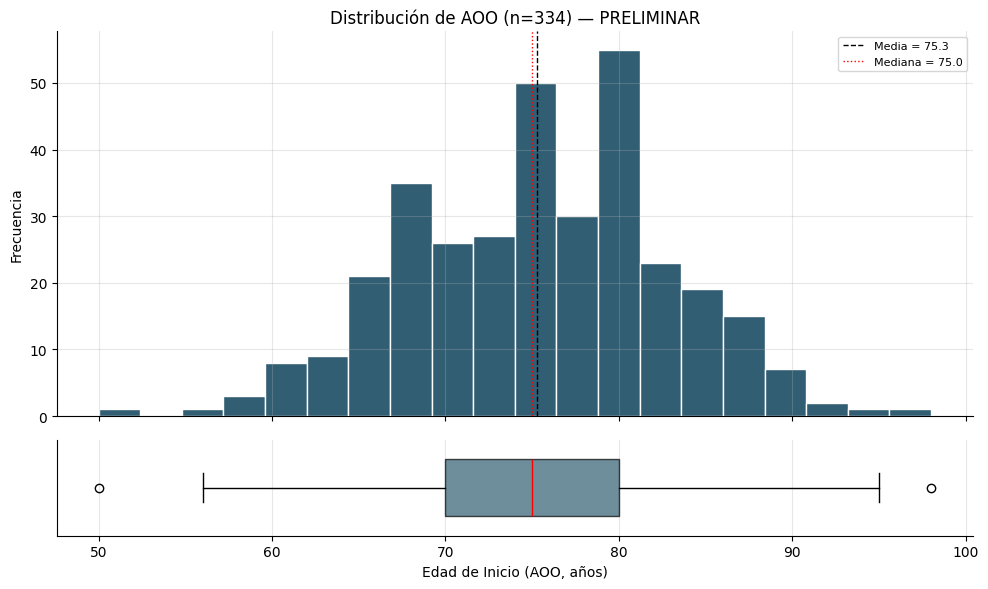

In [32]:
aoo = base_aoo["aoo"].dropna()

resumen_aoo = pd.DataFrame({
    "n": [aoo.count()],
    "Media": [aoo.mean()],
    "Mediana": [aoo.median()],
    "DE": [aoo.std()],
    "Mín": [aoo.min()],
    "Q1": [aoo.quantile(0.25)],
    "Q3": [aoo.quantile(0.75)],
    "Máx": [aoo.max()],
    "RIC": [aoo.quantile(0.75) - aoo.quantile(0.25)]
})

subtitulo("Estadísticas descriptivas de AOO (años)")
mostrar_tabla(
    resumen_aoo, alto=150, espacio=24,
    formato={"n": "{:.0f}", "Mín": "{:.0f}", "Máx": "{:.0f}"},
)

# Gráficos
fig, ax = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True,
    gridspec_kw={"height_ratios": [4, 1]}  # histograma 4 veces más alto que el boxplot
)

# Histograma (arriba)
ax[0].hist(aoo, bins=20, color="#315e73", edgecolor="white")
ax[0].axvline(aoo.mean(), color="black", linestyle="--", linewidth=1,
              label=f"Media = {aoo.mean():.1f}")
ax[0].axvline(aoo.median(), color="red", linestyle=":", linewidth=1,
              label=f"Mediana = {aoo.median():.1f}")
ax[0].set_ylabel("Frecuencia")
ax[0].set_title(f"Distribución de AOO (n={len(aoo)}) — PRELIMINAR")
ax[0].legend(fontsize=8)

# Boxplot horizontal (abajo)
ax[1].boxplot(
    aoo.dropna(), vert=False, widths=0.6, patch_artist=True,
    boxprops=dict(facecolor="#315e73", alpha=0.7),
    medianprops=dict(color="red")
)
ax[1].set_yticks([])  # quita el "1" del eje Y
ax[1].set_xlabel("Edad de Inicio (AOO, años)")

plt.tight_layout()
plt.show()

In [33]:
q1, q3 = aoo.quantile(0.25), aoo.quantile(0.75)
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr

outliers_mask = (aoo < lower_fence) | (aoo > upper_fence)
outlier_ids = base_aoo.loc[aoo[outliers_mask].index, "id"].tolist()
outlier_vals = aoo[outliers_mask]

print(f"Límites IQR: [{lower_fence:.1f}, {upper_fence:.1f}]")
print(f"n outliers detectados (no eliminados): {outliers_mask.sum()}")
if outliers_mask.sum() > 0:
    for i, v in zip(outlier_ids, outlier_vals):
        print(f"  ID {i}: AOO = {v:.0f} años")


Límites IQR: [55.0, 95.0]
n outliers detectados (no eliminados): 2
  ID 407: AOO = 50 años
  ID 500: AOO = 98 años


> **NOTA:** estos valores NO se eliminan del dataset. Pueden representar fenotipos de inicio muy temprano o muy tardío, de particular interés para el estudio de variantes modificadoras.

<br>

In [34]:
# Identificación de posibles fenotipos extremos de interés
p05, p95 = aoo.quantile(0.05), aoo.quantile(0.95)

extremos_tempranos = (base_aoo.loc[base_aoo["aoo"] <= p05, ["id", "aoo"]]
                      .sort_values("aoo")
                      .rename(columns={"id": "ID", "aoo": "AOO (años)"}))
extremos_tardios = (base_aoo.loc[base_aoo["aoo"] >= p95, ["id", "aoo"]]
                    .sort_values("aoo", ascending=False)
                    .rename(columns={"id": "ID", "aoo": "AOO (años)"}))

tabla_temp = tabla_extremos(extremos_tempranos,
                            f"AOO temprana (≤ P5 = {p05:.1f}) — n = {len(extremos_tempranos)}",
                            "#315e73")
tabla_tard = tabla_extremos(extremos_tardios,
                            f"AOO tardía (≥ P95 = {p95:.1f}) — n = {len(extremos_tardios)}",
                            "#a0522d")

display(HTML(f"""
<div style="display: flex; justify-content: center; gap: 60px; align-items: flex-start;
            flex-wrap: wrap; margin: 0.4rem 0 1rem 0;">
    <div>{tabla_temp}</div>
    <div>{tabla_tard}</div>
</div>
"""))

display(Markdown("*Estos IDs son de interés prioritario cuando se disponga de la base genética "
                 "(candidatos a portar variantes moduladoras).*"))

ID,AOO (años)
407,50
66,56
188,58
16,59
409,59
522,60
58,60
418,60
275,60
303,60


*Estos IDs son de interés prioritario cuando se disponga de la base genética (candidatos a portar variantes moduladoras).*

<br>

## **17. Calidad global de la base integrada**

In [35]:
nombres_faltantes = {
    "variable": "Variable",
    "n_faltantes": "N.º faltantes",
    "pct_faltantes": "% faltantes",
    "n_disponibles": "N.º disponibles",
    "decision_preliminar": "Decisión preliminar"
}

missing_integrada = pd.DataFrame({
    "n_faltantes": base_full.isna().sum(),
    "pct_faltantes": base_full.isna().mean() * 100,
    "n_disponibles": base_full.notna().sum()
}).sort_values("pct_faltantes", ascending=False)

# Dimensiones
# Dimensiones
print(f"Dimensiones de la base integrada: {base_full.shape[0]} filas × {base_full.shape[1]} columnas")

subtitulo("15 variables con mayor porcentaje de faltantes", espacio_antes=True)
mostrar_tabla(
    missing_integrada.head(15).rename_axis("variable").reset_index(),
    renombrar=nombres_faltantes,
    formato={"% faltantes": "{:.2f}"},
    espacio=24,
)

Dimensiones de la base integrada: 391 filas × 160 columnas


&nbsp;

**15 variables con mayor porcentaje de faltantes**

Variable,N.º faltantes,% faltantes,N.º disponibles
hx__si_la_respuesta_anterior_es_si_a_que_es_alergico,379,96.93,12
hx__si_respuesta_anterior_fue_afirmativa_hace_cuantos_anios_fuma,376,96.16,15
aoo_actualizada,344,87.98,47
hx__en_que_fecha_le_realizaron_la_cirugia,334,85.42,57
hx__si_la_respuesta_anterior_fue_si_que_cirugia_le_han_realizado,316,80.82,75
hx__si_la_respuesta_anterior_es_afirmativa_cuantas_personas_han_tenido_o_tienen_alzheimer_en_su_familia,221,56.52,170
hx__que_parentesco_tienen_con_usted,217,55.50,174
aoo_original,104,26.60,287
hx__antecedentes,92,23.53,299
hx__si_la_respuesta_anterior_fue_si_que_medicamentos_esta_consumiendo,68,17.39,323


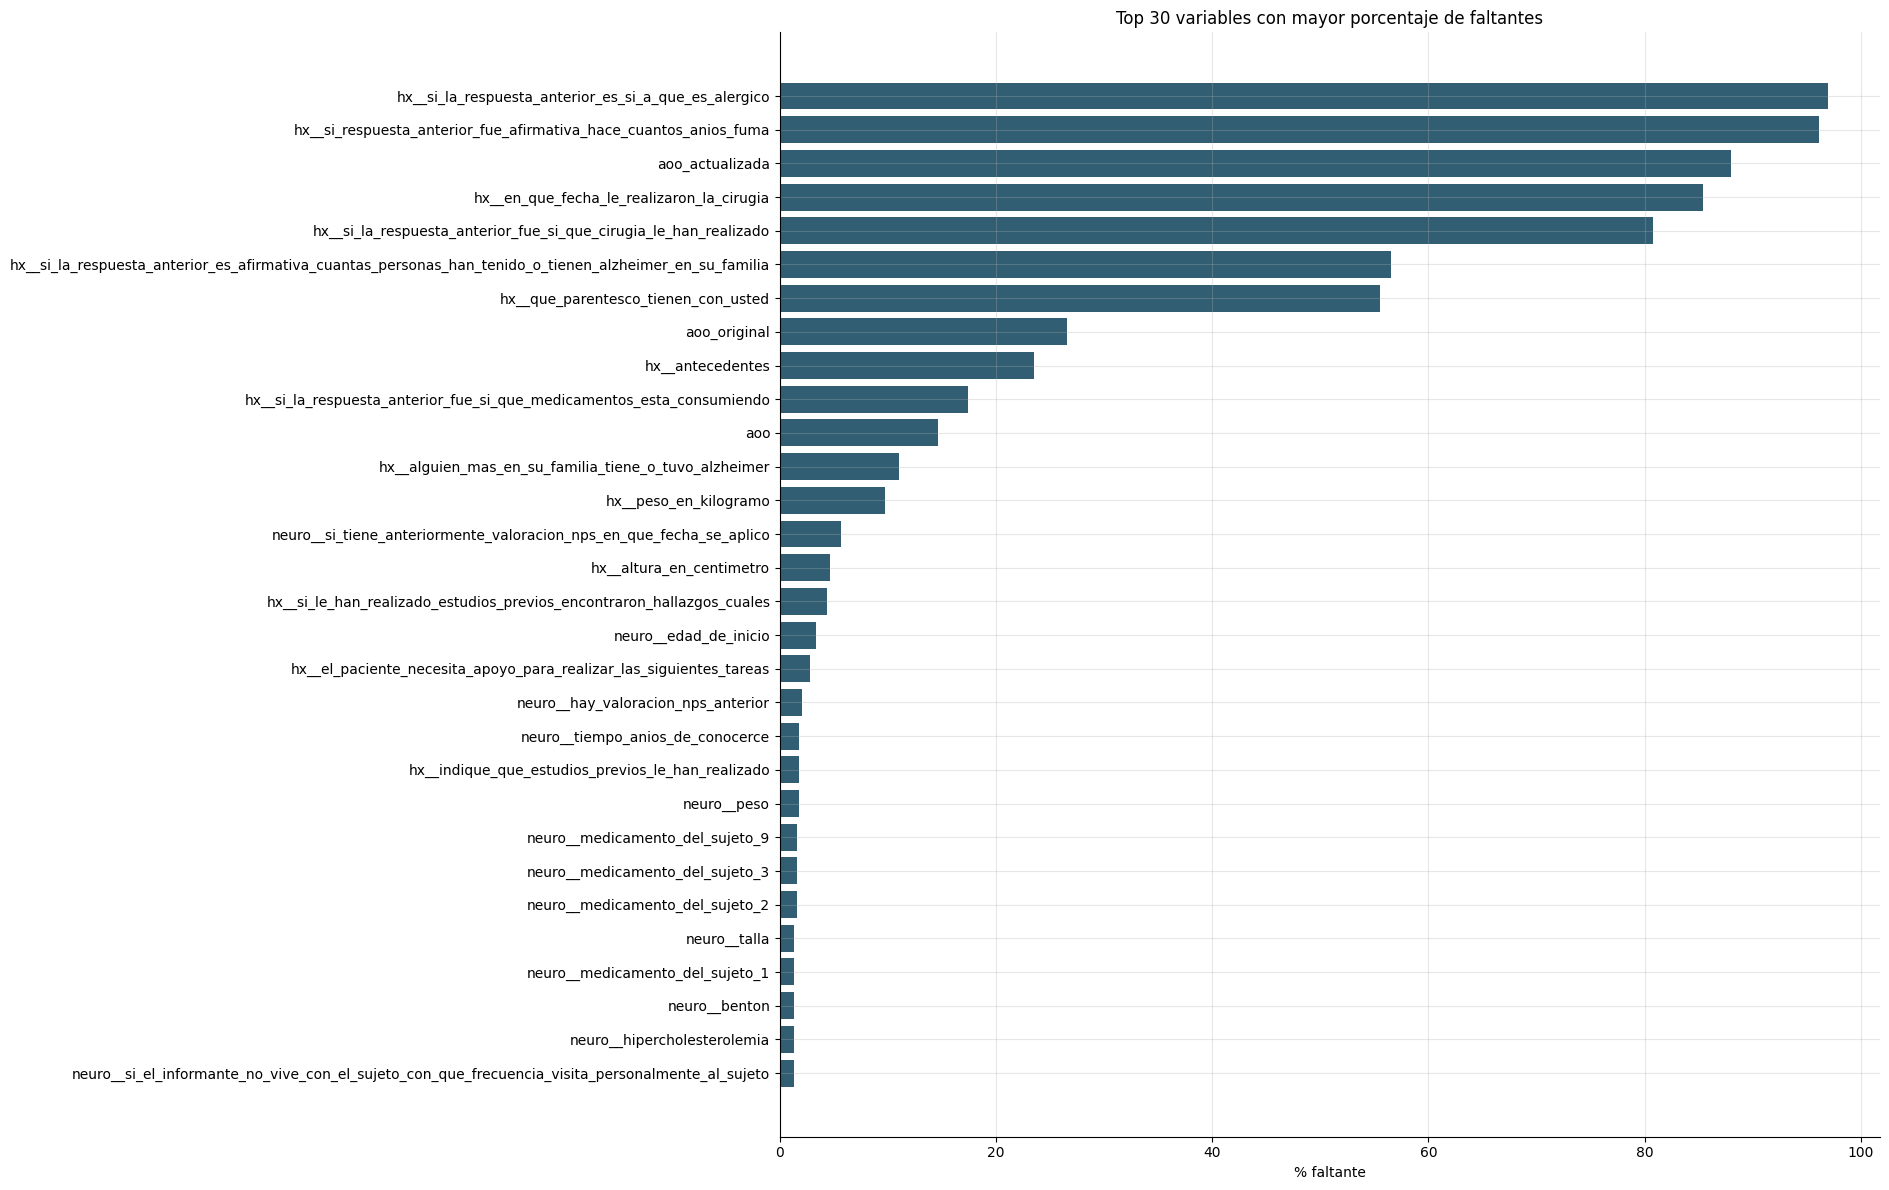

In [36]:
top_missing = missing_integrada.head(30).sort_values("pct_faltantes")

fig, ax = plt.subplots(figsize=(19, 12))
ax.barh(top_missing.index, top_missing["pct_faltantes"], color='#315e73')
ax.set_title("Top 30 variables con mayor porcentaje de faltantes")
ax.set_xlabel("% faltante")
plt.tight_layout()
plt.show()

In [37]:
tabla_faltantes = pd.DataFrame({
    "variable": base_full.columns,
    "n_faltantes": base_full.isna().sum().values,
    "pct_faltantes": (
        base_full.isna().mean().values * 100
    )
})

n_variables_con_faltantes = (
    tabla_faltantes["n_faltantes"] > 0
).sum()

print(
    "Variables con al menos un faltante:",
    n_variables_con_faltantes
)

print(
    "Total de columnas en base_full:",
    len(tabla_faltantes)
)

print(
    "Total de celdas faltantes:",
    tabla_faltantes["n_faltantes"].sum()
)

Variables con al menos un faltante: 145
Total de columnas en base_full: 160
Total de celdas faltantes: 3125


### **17.1. Estrategia de manejo de datos faltantes**

In [38]:
tabla_faltantes["decision_preliminar"] = np.select(
    [
        tabla_faltantes["pct_faltantes"] == 0,
        tabla_faltantes["pct_faltantes"] <= 5,
        tabla_faltantes["pct_faltantes"] <= 20,
        tabla_faltantes["pct_faltantes"] > 20,
    ],
    [
        "Sin acción",
        "Imputación probablemente innecesaria / evaluar",
        "Candidata a imputación",
        "Revisar exclusión o naturaleza estructural",
    ],
    default="Revisar",
)

subtitulo("20 variables con mayor porcentaje de faltantes")
mostrar_tabla(
    tabla_faltantes.sort_values("pct_faltantes", ascending=False).head(20),
    alto=400, espacio=24,
    renombrar=nombres_faltantes,
    formato={"% faltantes": "{:.2f}", "N.º faltantes": "{:.0f}"},
)

**20 variables con mayor porcentaje de faltantes**

Variable,N.º faltantes,% faltantes,Decisión preliminar
hx__si_la_respuesta_anterior_es_si_a_que_es_alergico,379,96.93,Revisar exclusión o naturaleza estructural
hx__si_respuesta_anterior_fue_afirmativa_hace_cuantos_anios_fuma,376,96.16,Revisar exclusión o naturaleza estructural
aoo_actualizada,344,87.98,Revisar exclusión o naturaleza estructural
hx__en_que_fecha_le_realizaron_la_cirugia,334,85.42,Revisar exclusión o naturaleza estructural
hx__si_la_respuesta_anterior_fue_si_que_cirugia_le_han_realizado,316,80.82,Revisar exclusión o naturaleza estructural
hx__si_la_respuesta_anterior_es_afirmativa_cuantas_personas_han_tenido_o_tienen_alzheimer_en_su_familia,221,56.52,Revisar exclusión o naturaleza estructural
hx__que_parentesco_tienen_con_usted,217,55.50,Revisar exclusión o naturaleza estructural
aoo_original,104,26.60,Revisar exclusión o naturaleza estructural
hx__antecedentes,92,23.53,Revisar exclusión o naturaleza estructural
hx__si_la_respuesta_anterior_fue_si_que_medicamentos_esta_consumiendo,68,17.39,Candidata a imputación


In [39]:
# Base preservada para etapas posteriores:
base_sin_imputar = base_full.copy()

print("Base preservada sin imputación:")
print(base_sin_imputar.shape)

Base preservada sin imputación:
(391, 160)


In [40]:
# Variables excluidas de la regla general de faltantes
excluir_regla_faltantes = [
    "id", "aoo", "aoo_original", "aoo_actualizada",
    "match_neuro", "match_moca",
    "inconsistente_con_neuro", "inconsistente_con_hx",
    "estado_consistencia_aoo"
]

tabla_faltantes_modelo = tabla_faltantes[
    ~tabla_faltantes["variable"].isin(excluir_regla_faltantes)
].copy()

mostrar_tabla(
    tabla_faltantes_modelo.sort_values("pct_faltantes", ascending=False),
    renombrar=nombres_faltantes,
    formato={"% faltantes": "{:.2f}"}
)

Variable,N.º faltantes,% faltantes,Decisión preliminar
hx__si_la_respuesta_anterior_es_si_a_que_es_alergico,379,96.93,Revisar exclusión o naturaleza estructural
hx__si_respuesta_anterior_fue_afirmativa_hace_cuantos_anios_fuma,376,96.16,Revisar exclusión o naturaleza estructural
hx__en_que_fecha_le_realizaron_la_cirugia,334,85.42,Revisar exclusión o naturaleza estructural
hx__si_la_respuesta_anterior_fue_si_que_cirugia_le_han_realizado,316,80.82,Revisar exclusión o naturaleza estructural
hx__si_la_respuesta_anterior_es_afirmativa_cuantas_personas_han_tenido_o_tienen_alzheimer_en_su_familia,221,56.52,Revisar exclusión o naturaleza estructural
hx__que_parentesco_tienen_con_usted,217,55.50,Revisar exclusión o naturaleza estructural
hx__antecedentes,92,23.53,Revisar exclusión o naturaleza estructural
hx__si_la_respuesta_anterior_fue_si_que_medicamentos_esta_consumiendo,68,17.39,Candidata a imputación
hx__alguien_mas_en_su_familia_tiene_o_tuvo_alzheimer,43,11.00,Candidata a imputación
hx__peso_en_kilogramo,38,9.72,Candidata a imputación


### **Decisión sobre imputación de datos faltantes**

En esta etapa del análisis exploratorio no se realizará imputación de valores faltantes. El objetivo actual es describir la calidad y estructura real de los datos, por lo que modificar los valores faltantes alteraría las distribuciones originales y podría ocultar problemas de calidad o patrones de ausencia relevantes.

Además, la imputación no debe realizarse de forma global antes de definir el esquema de modelamiento. En un contexto predictivo, calcular valores de imputación utilizando toda la base antes de separar conjuntos de entrenamiento y prueba puede generar data leakage, ya que la información del conjunto de prueba influiría indirectamente en el conjunto de entrenamiento.

Por esta razón, las variables se clasifican únicamente de forma preliminar según su porcentaje y naturaleza de datos faltantes. Las variables con más del 20% de faltantes reales serán revisadas para una posible exclusión del modelamiento, salvo que exista una justificación clínica o que la ausencia sea estructural. Las variables con hasta 20% de faltantes podrán considerarse posteriormente para imputación según su tipo y relevancia.

La variable `AOO`, al ser el desenlace principal del estudio, no será imputada. Los análisis que dependan de `AOO` se realizarán únicamente sobre los pacientes con un valor válido.

La estrategia definitiva de imputación se aplicará en la fase de modelamiento y se estimará exclusivamente con los datos de entrenamiento o dentro de un pipeline de validación, evitando así fuga de información.

<br>

## **18. Variables constantes, casi constantes y cardinalidad**

In [41]:
nunique = base_full.nunique(dropna=True)

# % que representa el valor más frecuente (sobre los datos no faltantes)
pct_moda = base_full.apply(
    lambda s: s.value_counts(normalize=True, dropna=True).iloc[0] * 100
    if s.notna().any() else np.nan
)

resumen_unicos = pd.DataFrame({
    "n_unicos": nunique,
    "valor_mas_frecuente": base_full.mode(dropna=True).iloc[0],
    "pct_valor_mas_frecuente": pct_moda
}).rename_axis("variable").reset_index()

nombres_unicos = {
    "variable": "Variable",
    "n_unicos": "N.º valores únicos",
    "valor_mas_frecuente": "Valor más frecuente",
    "pct_valor_mas_frecuente": "% valor más frecuente"
}

# 1. Variables constantes
def fmt_valor(v):
    if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
        return f"{v:.0f}" if float(v).is_integer() else f"{v:.2f}"
    return str(v)

formato_unicos = {"% valor más frecuente": "{:.1f}", "Valor más frecuente": fmt_valor}

# 1. Variables constantes
constantes = resumen_unicos[resumen_unicos["n_unicos"] <= 1]

subtitulo(f"Variables constantes ({len(constantes)})")
mostrar_tabla(constantes, alto=250, espacio=32,
              renombrar=nombres_unicos, formato=formato_unicos)

# 2. Variables con 2 o 3 valores únicos (criterio original)
dos_tres_valores = (resumen_unicos[resumen_unicos["n_unicos"].between(2, 3)]
                    .sort_values("pct_valor_mas_frecuente", ascending=False))

subtitulo(f"Variables con 2 o 3 valores únicos ({len(dos_tres_valores)})")
mostrar_tabla(dos_tres_valores, alto=300, espacio=24,
              renombrar=nombres_unicos, formato=formato_unicos)


**Variables constantes (10)**

Variable,N.º valores únicos,Valor más frecuente,% valor más frecuente
neuro__dx,1,1,100.0
neuro__idioma,1,2,100.0
neuro__angioplastia_endarterectomia_stent,1,0,100.0
neuro__bypass_cardiaco_coronario,1,0,100.0
neuro__traumatismo_de_craneo_encefalico_tce,1,0,100.0
neuro__niveles_de_vitamina_d,1,0,100.0
neuro__trastorno_de_estres_postraumatico_tept,1,0,100.0
neuro__trastorno_bipolar,1,0,100.0
neuro__trastorno_obsesivo_compulsivo_toc,1,0,100.0
neuro__trastornos_neuropsiquiatricos_del_desarrollo_por_ejemplo_trastorno_del_espectro_autista_tea_deficit_de_atencion_con_hiperactividad_tdah_dislexia,1,0,100.0


**Variables con 2 o 3 valores únicos (34)**

Variable,N.º valores únicos,Valor más frecuente,% valor más frecuente
match_moca,2,True,99.7
neuro__incontinencia_fecal,2,0,99.7
neuro__deficiencia_de_b12,2,0,99.7
neuro__estudio_cerebral_electroencefalograma_eeg,2,1,99.7
neuro__otro_idoma,3,2,99.5
neuro__artritis,2,0,99.5
neuro__incontinencia_urinaria,2,0,99.5
neuro__parkinson,2,0,99.5
match_neuro,2,True,99.2
neuro__esquizofrenia,2,0,99.2


<br>

## **19. Limpieza especial de tabaquismo**

In [42]:
col_anios_fumando = next(
    (c for c in demo_norm if "numero_total_de_anios_que_ha_fumado" in c),
    None
)

if col_anios_fumando is not None:
    base_full["anios_fumando_limpio"] = pd.to_numeric(
        base_full[col_anios_fumando],
        errors="coerce"
    )

    n_99 = (base_full["anios_fumando_limpio"] == 99).sum()

    base_full.loc[
        base_full["anios_fumando_limpio"] == 99,
        "anios_fumando_limpio"
    ] = np.nan

    print(f"Valores 99 recodificados como faltantes: {n_99}")

    # Resumen descriptivo (horizontal)
    resumen_fumar = (base_full["anios_fumando_limpio"]
                     .describe()
                     .to_frame().T
                     .rename(columns={
                         "count": "n", "mean": "Media", "std": "DE",
                         "min": "Mín", "25%": "Q1", "50%": "Mediana",
                         "75%": "Q3", "max": "Máx"
                     }))
    subtitulo("Resumen de años de tabaquismo", espacio_antes=True)
    mostrar_tabla(resumen_fumar, alto=150, formato={"n": "{:.0f}"}, centrar=True, espacio=32)

    # Frecuencia de cada valor
    frec_fumar = (base_full["anios_fumando_limpio"]
                  .value_counts(dropna=False)
                  .sort_index()
                  .rename_axis("Años fumando")
                  .reset_index(name="Frecuencia"))
    subtitulo("Frecuencia de cada valor")
    mostrar_tabla(frec_fumar, alto=300, decimales=0, centrar=True, espacio=24)

Valores 99 recodificados como faltantes: 13


&nbsp;

**Resumen de años de tabaquismo**

n,Media,DE,Mín,Q1,Mediana,Q3,Máx
342,3.93,10.17,0.00,0.00,0.00,0.00,70.00


**Frecuencia de cada valor**

Años fumando,Frecuencia
0,259
1,6
2,7
3,5
4,2
5,5
6,1
7,2
9,3
10,14


Después de recodificar el valor 99 = desconocido como faltante, se dispone de información válida sobre años de tabaquismo para 342 de los 391 pacientes. En total quedaron 49 registros faltantes, de los cuales 13 correspondían explícitamente al código 99.

La distribución de los años de tabaquismo está fuertemente concentrada en cero: 259 pacientes registran 0 años de consumo, equivalentes aproximadamente al 75,7% de quienes tienen un valor válido. La mediana, el primer cuartil y el tercer cuartil son todos iguales a 0, lo que confirma que la mayor parte de la cohorte no presenta años de tabaquismo acumulado registrados.

Entre los pacientes con valores positivos existe una distribución muy asimétrica hacia la derecha, con duraciones que van desde 1 hasta 70 años. Por esta razón, la media de 3,93 años es considerablemente mayor que la mediana de 0 y no representa adecuadamente al paciente típico de la cohorte. Se observan algunos participantes con exposiciones prolongadas, incluyendo registros de 20, 30, 40, 50, 57 y hasta 70 años.

En conjunto, la variable muestra una cohorte predominantemente sin exposición acumulada registrada, junto con un grupo menor de pacientes con antecedentes de tabaquismo de duración variable y, en algunos casos, prolongada.

<br>

## **20. Variables neuropsicológicas: exploración y reducción**

Las neuropsicológicas completas se usarán para:

- calidad y faltantes;

- rangos;

- variabilidad;

- correlaciones;

- redundancia;

- selección de representantes por dominio.

No se pretende incluirlas todas en el modelo principal de AOO.

In [43]:
from funciones.funciones_reduccion import *

convertidas_neuro = convertir_numericas_probables(base_full, neuro_norm)

print("Variables neuro convertidas a numéricas:", len(convertidas_neuro))

Variables neuro convertidas a numéricas: 54


### **20.1. Calidad de todas las variables neuropsicológicas**

In [44]:
neuro_num = [
    c for c in neuro_norm
    if c in base_full.columns and pd.api.types.is_numeric_dtype(base_full[c])
]

calidad_neuro = pd.DataFrame({
    "variable": neuro_num,
    "n_disponibles": [base_full[c].notna().sum() for c in neuro_num],
    "pct_faltantes": [base_full[c].isna().mean() * 100 for c in neuro_num],
    "n_unicos": [base_full[c].nunique(dropna=True) for c in neuro_num],
    "media": [base_full[c].mean() for c in neuro_num],
    "mediana": [base_full[c].median() for c in neuro_num],
    "DE": [base_full[c].std() for c in neuro_num]
})

nombres_calidad = {
    "variable": "Variable",
    "n_disponibles": "N.º disponibles",
    "pct_faltantes": "% faltantes",
    "n_unicos": "N.º valores únicos",
    "media": "Media",
    "mediana": "Mediana",
    "DE": "DE"
}

mostrar_tabla(
    calidad_neuro.sort_values(["pct_faltantes", "n_unicos"]),
    alto=400,
    renombrar=nombres_calidad,
    formato={
        "N.º disponibles": "{:.0f}",
        "N.º valores únicos": "{:.0f}",
        "% faltantes": "{:.1f}"
    }
)

Variable,N.º disponibles,% faltantes,N.º valores únicos,Media,Mediana,DE
neuro__fast,388,0.8,5,3.51,3.00,0.83
neuro__ikatz,388,0.8,7,1.63,0.00,2.17
neuro__barthel,388,0.8,12,37.37,50.00,18.15
neuro__lawton_y_brody,388,0.8,14,2.70,2.00,4.54
neuro__esc_deterioroglobal,387,1.0,6,3.84,4.00,0.55
neuro__mmse,385,1.5,31,16.28,19.00,9.55
neuro__quejas_subjetivas,383,2.0,7,2.12,2.00,2.15
neuro__hay_valoracion_nps_anterior,382,2.3,2,0.01,0.00,0.10
neuro__fcrocop,382,2.3,36,8.06,2.00,10.84
neuro__taavrey1,380,2.8,7,1.66,2.00,1.49


### **20.2. Exploración neuropsicológica por dominios**

&nbsp;

#### Metadatos nps

*0 variables numéricas*

Sin variables numéricas en este grupo.

&nbsp;

#### Cognicion global

*1 variables numéricas*

Variable,n,Media,DE,Mín,Q1,Mediana,Q3,Máx
mmse,385,16.28,9.55,0.00,10.00,19.00,24.00,30.00


&nbsp;

#### Memoria

*11 variables numéricas*

Variable,n,Media,DE,Mín,Q1,Mediana,Q3,Máx
cmweschler,377,1.85,2.93,0.00,0.00,0.00,3.00,33.00
taavrey1,380,1.66,1.49,0.00,0.00,2.00,3.00,6.00
taavrey2,380,2.41,1.78,0.00,1.00,2.00,4.00,8.00
taavrey3,380,2.86,2.00,0.00,1.00,3.00,4.00,8.00
taavrey4,380,3.01,2.17,0.00,1.75,3.00,4.00,13.00
taavrey5,380,3.18,2.31,0.00,1.00,3.00,5.00,11.00
taavreyb1,380,1.35,1.28,0.00,0.00,1.00,2.00,6.00
taavrey6,380,1.49,1.75,0.00,0.00,1.00,3.00,9.00
taavrey7,379,0.84,1.73,0.00,0.00,0.00,1.00,19.00
taavrey_rec_si,376,7.26,5.65,0.00,0.00,8.00,13.00,15.00


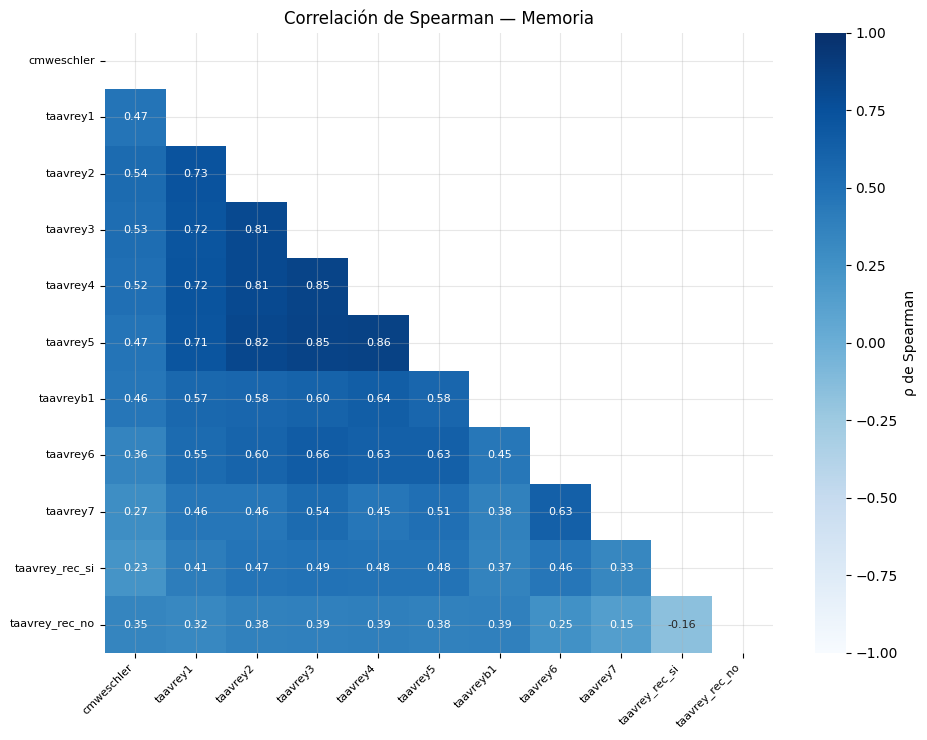

&nbsp;

#### Fluidez verbal

*5 variables numéricas*

Variable,n,Media,DE,Mín,Q1,Mediana,Q3,Máx
fvsa,378,6.06,4.71,0.00,2.00,6.00,9.00,20.00
fvsc,378,6.21,4.24,0.00,3.00,6.00,9.00,22.00
fvff,375,3.64,3.94,0.00,0.00,2.00,6.00,18.00
fvfa,375,3.23,3.65,0.00,0.00,2.00,5.00,19.00
fvfs,374,3.38,3.86,0.00,0.00,2.00,5.75,19.00


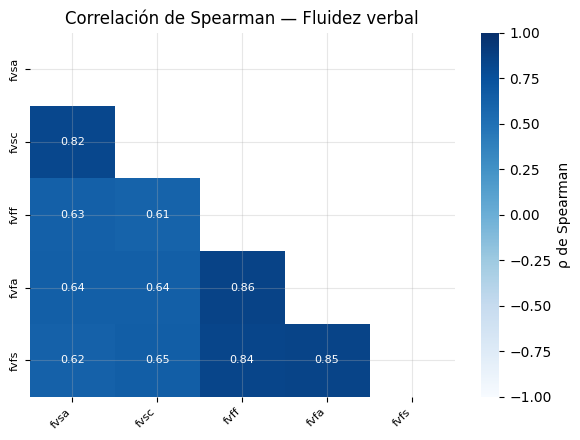

&nbsp;

#### Lenguaje

*4 variables numéricas*

Variable,n,Media,DE,Mín,Q1,Mediana,Q3,Máx
token,375,15.91,10.61,0.00,9.00,16.00,24.00,36.00
tbn_espontanea,380,19.19,14.41,0.00,5.75,18.00,31.00,52.00
tbn_semantica,380,1.46,2.41,0.00,0.00,0.00,2.00,13.00
tbn_total,380,20.48,15.12,0.00,6.00,19.50,33.00,53.00


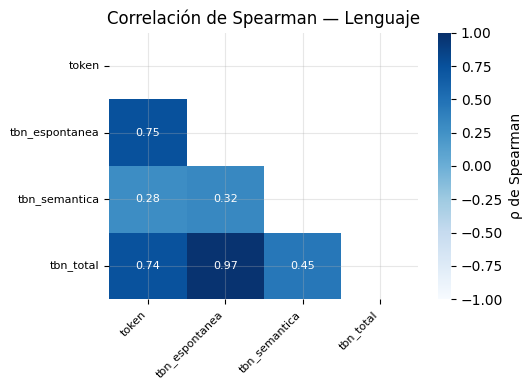

&nbsp;

#### Praxia visuoconstruccion

*3 variables numéricas*

Variable,n,Media,DE,Mín,Q1,Mediana,Q3,Máx
fcrocop,382,8.06,10.84,0.00,0.00,2.00,15.00,36.00
fcroevo,377,1.05,2.54,0.00,0.00,0.00,1.00,20.00
reloj,367,2.89,3.28,0.00,0.00,2.00,5.00,10.00


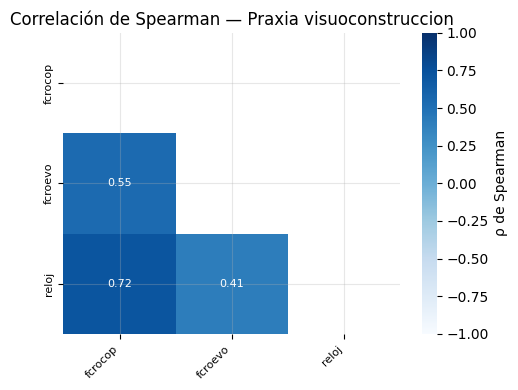

&nbsp;

#### Funcion ejecutiva atencion

*9 variables numéricas*

Variable,n,Media,DE,Mín,Q1,Mediana,Q3,Máx
tspal,366,30.23,29.11,0.00,0.00,29.50,54.00,140.00
tscol,365,21.21,20.15,0.00,0.00,21.00,40.00,95.00
tspalcol,365,9.67,11.54,0.00,0.00,6.00,16.00,64.00
tmtb,306,18.94,73.39,0.00,0.00,0.00,0.00,360.00
teac,361,8.70,6.93,0.00,0.00,11.00,15.00,16.00
twiscat,368,0.76,1.18,0.00,0.00,0.00,1.00,10.00
twisenp,367,7.39,10.01,0.00,0.00,5.00,11.00,84.00
twisep,367,18.31,16.40,0.00,0.00,18.00,29.00,86.00
twiscorresctas,370,12.22,13.00,0.00,0.00,11.00,19.00,96.00


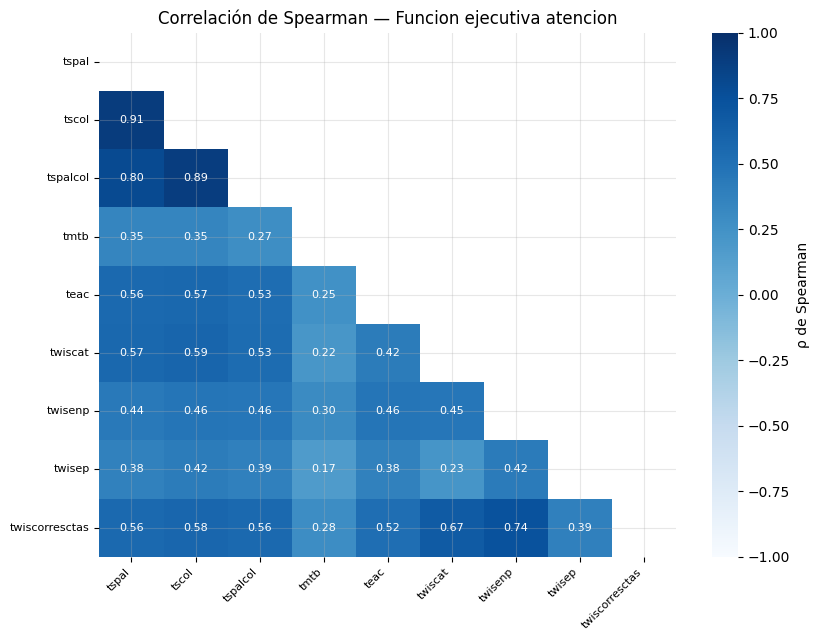

&nbsp;

#### Memoria semantica conocimiento

*3 variables numéricas*

Variable,n,Media,DE,Mín,Q1,Mediana,Q3,Máx
tsmydoral,363,3.68,7.39,0.00,0.00,0.00,4.00,42.00
tsmyd_escr,363,2.92,5.76,0.00,0.00,0.00,3.00,35.00
benton,365,0.87,1.32,0.00,0.00,0.00,1.00,7.00


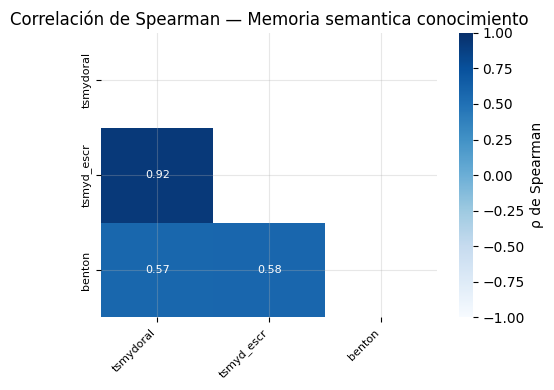

&nbsp;

#### Funcional afectivo quejas

*5 variables numéricas*

Variable,n,Media,DE,Mín,Q1,Mediana,Q3,Máx
yesavage,372,6.37,5.90,0.00,1.00,4.00,10.00,16.00
barthel,388,37.37,18.15,0.00,25.00,50.00,50.00,50.00
lawton_y_brody,388,2.70,4.54,0.00,1.00,2.00,3.00,30.00
ikatz,388,1.63,2.17,0.00,0.00,0.00,3.00,6.00
fast,388,3.51,0.83,2.00,3.00,3.00,4.00,16.00


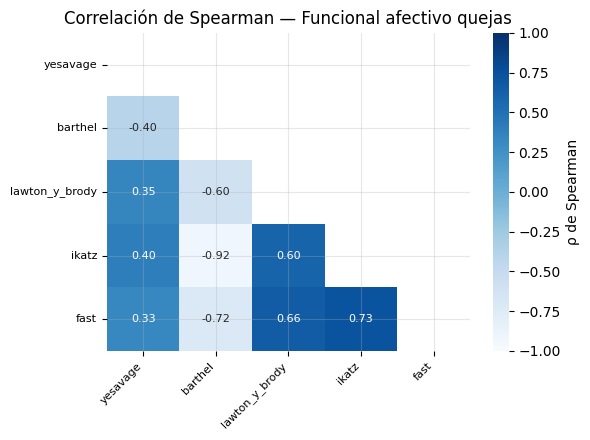

In [45]:
nombres_describe = {
    "variable": "Variable", "count": "n", "mean": "Media", "std": "DE",
    "min": "Mín", "25%": "Q1", "50%": "Mediana", "75%": "Q3", "max": "Máx"
}

for grupo, vars_orig in GRUPOS_NEURO.items():
    vars_norm = [
        f"neuro__{mapa_neuro_dict[v]}"
        for v in vars_orig
        if v in mapa_neuro_dict
    ]

    vars_num = [
        c for c in vars_norm
        if c in base_full.columns and pd.api.types.is_numeric_dtype(base_full[c])
    ]

    # Título del grupo
    nombre_grupo = grupo.replace("_", " ").capitalize()
    display(Markdown(f"&nbsp;\n\n#### {nombre_grupo}\n\n"
                     f"*{len(vars_num)} variables numéricas*"))

    if not vars_num:
        display(Markdown("Sin variables numéricas en este grupo."))
        continue

    # Descriptivos (sin el prefijo "neuro__")
    desc = (base_full[vars_num].describe().T
            .rename(index=lambda c: c.replace("neuro__", ""))
            .rename_axis("variable").reset_index())
    mostrar_tabla(desc, alto=300, renombrar=nombres_describe,
                  formato={"n": "{:.0f}"}, espacio=24)

    # Correlación de Spearman como mapa de calor
    if len(vars_num) >= 2:
        corr = base_full[vars_num].corr(method="spearman")
        etiquetas = [c.replace("neuro__", "") for c in vars_num]
        k = len(vars_num)

        fig, ax = plt.subplots(figsize=(max(5, 0.6 * k + 3), max(4, 0.5 * k + 2)))
        sns.heatmap(
            corr, mask=np.triu(np.ones_like(corr, dtype=bool)),  # solo triángulo inferior
            annot=k <= 12, fmt=".2f", annot_kws={"size": 8},
            cmap="Blues", vmin=-1, vmax=1, center=0,
            xticklabels=etiquetas, yticklabels=etiquetas,
            cbar_kws={"label": "ρ de Spearman"}, ax=ax
        )
        ax.set_title(f"Correlación de Spearman — {nombre_grupo}")
        plt.xticks(rotation=45, ha="right", fontsize=8)
        plt.yticks(fontsize=8)
        plt.tight_layout()
        plt.show()

### **20.3. Correlaciones y redundancia neuropsicológica**

In [46]:
corr_cols = [
    c for c in neuro_num
    if base_full[c].notna().sum() >= max(30, int(.50 * len(base_full)))
    and base_full[c].nunique(dropna=True) > 3
]

corr_neuro = base_full[corr_cols].corr(method="spearman")

pares = []
for i in range(len(corr_neuro.columns)):
    for j in range(i + 1, len(corr_neuro.columns)):
        rho = corr_neuro.iloc[i, j]
        if pd.notna(rho):
            pares.append([
                corr_neuro.index[i],
                corr_neuro.columns[j],
                rho,
                abs(rho)
            ])

pares_corr = pd.DataFrame(
    pares,
    columns=["variable_1", "variable_2", "rho_spearman", "abs_rho"]
).sort_values("abs_rho", ascending=False)

nombres_pares = {
    "variable_1": "Variable 1",
    "variable_2": "Variable 2",
    "rho_spearman": "ρ de Spearman"
}

tabla_pares = (pares_corr.head(60)
               .drop(columns="abs_rho")   # solo se usaba para ordenar
               .assign(variable_1=lambda d: d["variable_1"].str.replace("neuro__", ""),
                       variable_2=lambda d: d["variable_2"].str.replace("neuro__", "")))

print(f"Variables incluidas: {len(corr_cols)} | Pares evaluados: {len(pares_corr)}")

subtitulo("60 pares con mayor correlación (|ρ|)", espacio_antes=True)
mostrar_tabla(tabla_pares, alto=400, renombrar=nombres_pares,
              formato={"ρ de Spearman": "{:.3f}"}, espacio=24, centrar=True)

Variables incluidas: 52 | Pares evaluados: 1326


&nbsp;

**60 pares con mayor correlación (|ρ|)**

Variable 1,Variable 2,ρ de Spearman
tbn_espontanea,tbn_total,0.972
barthel,ikatz,-0.924
tsmydoral,tsmyd_escr,0.923
tspal,tscol,0.905
tscol,tspalcol,0.893
taavrey4,taavrey5,0.860
fvff,fvfa,0.857
taavrey3,taavrey5,0.852
fvfa,fvfs,0.851
taavrey3,taavrey4,0.850


In [47]:
redundantes_fuertes = pares_corr[pares_corr["abs_rho"] >= .80]

if len(redundantes_fuertes) > 0:
    subtitulo(f"Pares redundantes con |ρ| ≥ 0.80 ({len(redundantes_fuertes)})")
    mostrar_tabla(
        redundantes_fuertes
        .drop(columns="abs_rho")
        .assign(variable_1=lambda d: d["variable_1"].str.replace("neuro__", ""),
                variable_2=lambda d: d["variable_2"].str.replace("neuro__", "")),
        alto=300,
        renombrar=nombres_pares,
        formato={"ρ de Spearman": "{:.3f}"},
        espacio=32,
        centrar=True,
    )
else:
    display(Markdown("No hay pares con correlación igual o mayor a 0.80."))

**Pares redundantes con |ρ| ≥ 0.80 (15)**

Variable 1,Variable 2,ρ de Spearman
tbn_espontanea,tbn_total,0.972
barthel,ikatz,-0.924
tsmydoral,tsmyd_escr,0.923
tspal,tscol,0.905
tscol,tspalcol,0.893
taavrey4,taavrey5,0.860
fvff,fvfa,0.857
taavrey3,taavrey5,0.852
fvfa,fvfs,0.851
taavrey3,taavrey4,0.850


La batería neuropsicológica contiene varios grupos de variables con fuerte redundancia interna. Esto sugiere que no es necesario incluir todas las pruebas simultáneamente en análisis posteriores, ya que algunas aportan información muy similar.

### **20.4. Variables clínicas/neuropsicológicas prioritarias**


In [48]:
tabla_reduccion_neuro = pd.DataFrame([
    {
        "grupo_redundante": "Denominación - TBN",
        "variable_conservada": "neuro__tbn_total",
        "variables_excluidas_modelo": "neuro__tbn_espontanea",
        "rho_aprox": 0.972,
        "motivo": "Correlación muy alta; se conserva una medida resumen."
    },
    {
        "grupo_redundante": "Memoria verbal - TAAV Rey",
        "variable_conservada": "neuro__taavrey5",
        "variables_excluidas_modelo": "neuro__taavrey2, neuro__taavrey3, neuro__taavrey4",
        "rho_aprox": "0.81–0.86",
        "motivo": "Alta correlación entre ensayos de aprendizaje; se conserva un ensayo representativo."
    },
    {
        "grupo_redundante": "Fluidez verbal fonológica",
        "variable_conservada": "neuro__fvff",
        "variables_excluidas_modelo": "neuro__fvfa, neuro__fvfs",
        "rho_aprox": "0.84–0.86",
        "motivo": "Alta redundancia entre tareas fonológicas."
    },
    {
        "grupo_redundante": "Stroop",
        "variable_conservada": "neuro__tscol",
        "variables_excluidas_modelo": "neuro__tspal, neuro__tspalcol",
        "rho_aprox": "0.89–0.91",
        "motivo": "Alta correlación entre condiciones de la prueba."
    },
    {
        "grupo_redundante": "Memoria semántica",
        "variable_conservada": "neuro__tsmydoral",
        "variables_excluidas_modelo": "neuro__tsmyd_escr",
        "rho_aprox": 0.923,
        "motivo": "Las versiones oral y escrita presentan información muy similar."
    },
    {
        "grupo_redundante": "Funcionalidad",
        "variable_conservada": "neuro__barthel",
        "variables_excluidas_modelo": "neuro__ikatz",
        "rho_aprox": -0.924,
        "motivo": "Alta relación inversa; ambas escalas reflejan dimensiones funcionales relacionadas."
    }
])

nombres_reduccion = {
    "grupo_redundante": "Grupo redundante",
    "variable_conservada": "Variable conservada",
    "variables_excluidas_modelo": "Variables excluidas del modelo",
    "rho_aprox": "ρ aprox.",
    "motivo": "Motivo"
}

tabla_mostrar = tabla_reduccion_neuro.copy()
for col in ["variable_conservada", "variables_excluidas_modelo"]:
    tabla_mostrar[col] = tabla_mostrar[col].str.replace("neuro__", "")

mostrar_tabla(
    tabla_mostrar,
    alto=450,
    renombrar=nombres_reduccion,
    formato={"ρ aprox.": lambda v: f"{v:.3f}" if isinstance(v, float) else v},
    ajustar_texto=True,
    una_linea=["ρ aprox."]
)

Grupo redundante,Variable conservada,Variables excluidas del modelo,ρ aprox.,Motivo
Denominación - TBN,tbn_total,tbn_espontanea,0.972,Correlación muy alta; se conserva una medida resumen.
Memoria verbal - TAAV Rey,taavrey5,"taavrey2, taavrey3, taavrey4",0.81–0.86,Alta correlación entre ensayos de aprendizaje; se conserva un ensayo representativo.
Fluidez verbal fonológica,fvff,"fvfa, fvfs",0.84–0.86,Alta redundancia entre tareas fonológicas.
Stroop,tscol,"tspal, tspalcol",0.89–0.91,Alta correlación entre condiciones de la prueba.
Memoria semántica,tsmydoral,tsmyd_escr,0.923,Las versiones oral y escrita presentan información muy similar.
Funcionalidad,barthel,ikatz,-0.924,Alta relación inversa; ambas escalas reflejan dimensiones funcionales relacionadas.


In [49]:
variables_neuro_reducidas = [
    # Cognición global
    "neuro__mmse",
    "moca__moca",
    "neuro__fast",

    # Una representativa de cada grupo redundante
    "neuro__tbn_total",
    "neuro__taavrey5",
    "neuro__fvff",
    "neuro__tscol",
    "neuro__tsmydoral",
    "neuro__barthel"
]

# Dejar solo las que realmente existen en base_full
variables_neuro_reducidas = [
    v for v in variables_neuro_reducidas
    if v in base_full.columns
]

print("Variables neuropsicológicas seleccionadas:")
for v in variables_neuro_reducidas:
    print("-", v)

Variables neuropsicológicas seleccionadas:
- neuro__mmse
- moca__moca
- neuro__fast
- neuro__tbn_total
- neuro__taavrey5
- neuro__fvff
- neuro__tscol
- neuro__tsmydoral
- neuro__barthel


In [50]:
variables_neuro_excluidas_redundancia = [
    "neuro__tbn_espontanea",
    "neuro__taavrey2",
    "neuro__taavrey3",
    "neuro__taavrey4",
    "neuro__fvfa",
    "neuro__fvfs",
    "neuro__tspal",
    "neuro__tspalcol",
    "neuro__tsmyd_escr",
    "neuro__ikatz"
]

variables_neuro_excluidas_redundancia = [
    v for v in variables_neuro_excluidas_redundancia
    if v in base_full.columns
]

print("N variables conservadas:", len(variables_neuro_reducidas))
print("N variables excluidas por redundancia:", len(variables_neuro_excluidas_redundancia))

N variables conservadas: 9
N variables excluidas por redundancia: 10


Las correlaciones de Spearman permitieron identificar grupos de pruebas con fuerte redundancia estadística (|rho| ≥ 0.80). Estas variables no se eliminan de la base original, sino que se excluyen únicamente del conjunto destinado a análisis posteriores. Para cada grupo redundante se conserva una variable representativa, considerando correlación, interpretabilidad clínica, completitud y facilidad de interpretación. La selección es preliminar y podrá ajustarse con criterio del investigador.

### **20.5. Variables clínicas/neuropsicológicas prioritarias**

Se priorizan:

- MMSE

- MoCA

- FAST

Estas sirven principalmente para **caracterización clínica y análisis secundario**.

No deben incluirse automáticamente como predictores del AOO, porque pueden haberse medido después del inicio de la enfermedad.

In [51]:
core_vars = ["neuro__mmse", "moca__moca", "neuro__fast"]
core_vars = [c for c in core_vars if c in base_full.columns]

for c in core_vars:
    base_full[c] = pd.to_numeric(base_full[c], errors="coerce")

etiquetas_core = {"neuro__mmse": "MMSE", "moca__moca": "MoCA", "neuro__fast": "FAST"}

print(f"Variables clínicas centrales incluidas: {', '.join(etiquetas_core.get(c, c) for c in core_vars)}")

# Descriptivos
desc_core = (base_full[core_vars].describe().T
             .rename(index=etiquetas_core)
             .rename_axis("variable").reset_index())
subtitulo("Estadísticas descriptivas", espacio_antes=True)
mostrar_tabla(desc_core, alto=200, renombrar=nombres_describe,
              formato={"n": "{:.0f}"}, espacio=32)

# Correlación de Spearman
corr_core = (base_full[core_vars].corr(method="spearman")
             .rename(index=etiquetas_core, columns=etiquetas_core)
             .rename_axis("").reset_index())
subtitulo("Correlación de Spearman")
mostrar_tabla(corr_core, alto=200, decimales=3, espacio=24)

Variables clínicas centrales incluidas: MMSE, MoCA, FAST


&nbsp;

**Estadísticas descriptivas**

Variable,n,Media,DE,Mín,Q1,Mediana,Q3,Máx
MMSE,385,16.28,9.55,0.00,10.00,19.00,24.00,30.00
MoCA,389,8.88,7.01,0.00,3.00,8.00,15.00,28.00
FAST,388,3.51,0.83,2.00,3.00,3.00,4.00,16.00


**Correlación de Spearman**

,MMSE,MoCA,FAST
MMSE,1.000,0.831,-0.527
MoCA,0.831,1.000,-0.521
FAST,-0.527,-0.521,1.000


### **20.5. Tabla para justificar reducción neuropsicológica**

Se evalúa la calidad de las variables neuropsicológicas considerando su porcentaje de datos faltantes y su variabilidad. Se consideran inicialmente de alta completitud aquellas con ≤10% de valores faltantes y con variabilidad suficiente aquellas que presentan más de 5 valores únicos. Estos criterios no determinan por sí solos la selección final, sino que sirven como apoyo junto con la relevancia clínica, la redundancia entre pruebas y el riesgo de data leakage.

In [52]:
tabla_seleccion_neuro = calidad_neuro.copy()

tabla_seleccion_neuro["alta_completitud"] = tabla_seleccion_neuro["pct_faltantes"] <= 10
tabla_seleccion_neuro["variabilidad_suficiente"] = tabla_seleccion_neuro["n_unicos"] > 5

nombres_seleccion = {
    **nombres_calidad,
    "alta_completitud": "Alta completitud (≤ 10% faltantes)",
    "variabilidad_suficiente": "Variabilidad suficiente (> 5 valores)"
}

si_no = lambda v: "Sí" if v else "No"

n_ambos = (tabla_seleccion_neuro["alta_completitud"]
           & tabla_seleccion_neuro["variabilidad_suficiente"]).sum()

subtitulo(f"Variables que cumplen ambos criterios: {n_ambos} de {len(tabla_seleccion_neuro)}")
mostrar_tabla(
    tabla_seleccion_neuro
    .sort_values(["alta_completitud", "variabilidad_suficiente", "pct_faltantes"],
                 ascending=[False, False, True])
    .assign(variable=lambda d: d["variable"].str.replace("neuro__", "")),
    alto=400,
    espacio=24,
    renombrar=nombres_seleccion,
    formato={
        "N.º disponibles": "{:.0f}",
        "N.º valores únicos": "{:.0f}",
        "% faltantes": "{:.1f}",
        "Alta completitud (≤ 10% faltantes)": si_no,
        "Variabilidad suficiente (> 5 valores)": si_no
    }
)

**Variables que cumplen ambos criterios: 46 de 54**

Variable,N.º disponibles,% faltantes,N.º valores únicos,Media,Mediana,DE,Alta completitud (≤ 10% faltantes),Variabilidad suficiente (> 5 valores)
barthel,388,0.8,12,37.37,50.00,18.15,Sí,Sí
lawton_y_brody,388,0.8,14,2.70,2.00,4.54,Sí,Sí
ikatz,388,0.8,7,1.63,0.00,2.17,Sí,Sí
esc_deterioroglobal,387,1.0,6,3.84,4.00,0.55,Sí,Sí
mmse,385,1.5,31,16.28,19.00,9.55,Sí,Sí
quejas_subjetivas,383,2.0,7,2.12,2.00,2.15,Sí,Sí
fcrocop,382,2.3,36,8.06,2.00,10.84,Sí,Sí
taavrey1,380,2.8,7,1.66,2.00,1.49,Sí,Sí
taavrey2,380,2.8,9,2.41,2.00,1.78,Sí,Sí
taavrey3,380,2.8,9,2.86,3.00,2.00,Sí,Sí


## **21. Exportación de la base de datos limpia**

En esta última sección, se exporta la base de datos limpia para continuar con los análisis univariados y bivariados, así como con el análisis de correlaciones, asociaciones y otras técnicas estadísticas que permitan profundizar en el comportamiento de las variables y en las relaciones entre ellas.

In [53]:
SALIDAS = Path("salidas")
SALIDAS.mkdir(exist_ok=True)

base_full.to_pickle(SALIDAS / "base_full.pkl")
diccionario.to_pickle(SALIDAS / "diccionario.pkl")

objetos = {
    "neuro_norm": neuro_norm,
    "demo_norm": demo_norm,
    "GRUPOS_DEMO": GRUPOS_DEMO,
    "GRUPOS_NEURO": GRUPOS_NEURO,
    "calidad_neuro": calidad_neuro,
    "tabla_seleccion_neuro": tabla_seleccion_neuro,
    "variables_neuro_reducidas": variables_neuro_reducidas,
    "variables_neuro_excluidas_redundancia": variables_neuro_excluidas_redundancia,
    "tabla_reduccion_neuro": tabla_reduccion_neuro,
}
with open(SALIDAS / "objetos_preprocesamiento.pkl", "wb") as f:
    pickle.dump(objetos, f)

print("base_full:", base_full.shape, "| diccionario:", diccionario.shape)

base_full: (391, 161) | diccionario: (149, 17)
